# E-mini Nasdaq-100 Futures (CME NQ1!) Research Poster: Data Audit, Metrics and Reference Visuals

- **Module:** 7CS079 Data Visualisation
- **Author:** Santiago Cruz | **ID:** 2584023
- **Research Poster:** Data Visualisation Using Tableau
- **Dataset:** `CME_MINI_DL_NQ1!_1D.csv`, CME Globex: E-mini Nasdaq-100 Futures Contract, Daily OHLC Bars, 30 Jun 1999 – 30 Oct 2026
- **Dataset Source:** TradingView
- **Date:** 31 October, 2026
- **The University of Wolverhampton**

The E-mini Nasdaq-100 future (ticker NQ, $20 × index) is the most heavily traded derivative on the NASDAQ-100 index. It trades almost 24 hours a day and tracks the cash index closely. This notebook:

1. audits the raw file, including futures-specific checks: exchange sessions, tick grid and contract rolls;
2. cleans it and derives the measures used on the poster;
3. exports `NQ_clean_for_tableau.csv` for Tableau;
4. computes every statistic quoted in the report, and tests how robust each finding is; and
5. renders reference versions of the six poster visualisations (V1–V6) and an A1 layout reference, which are rebuilt in Tableau for the poster.

**Research objectives:** **O1 trend**: the long-run path and its interruptions. **O2 volatility**: how risk is distributed over time and across days. **O3 regimes**: whether the 252-day moving average separates calm and turbulent markets.

### Research questions and audience

| Objective | Research question | Answered by |
|---|---|---|
| O1 Trend | **RQ1** How deep and how long were the interruptions to the long-run trend? | V1, V2, V3; §5.1, §5.4, §5.5 |
| O2 Volatility | **RQ2** Is risk spread evenly over time and across days, as a bell-curve model assumes? | V4, V5; §5.2, §5.3, §5.9 |
| O3 Regimes | **RQ3** Does a simple 252-day moving average separate calm from turbulent markets? | V6; §5.6, §5.8 |

**Audience:** non-specialists with exposure to the Nasdaq-100 (retail investors, pension savers holding technology trackers, and business students) and early-career traders. The poster turns 27 years of daily data into a story about what long-run averages hide: **data → story → audience → tools** (Week 1).

### Where this notebook supports each rubric criterion

| Rubric criterion | Evidence in this notebook |
|---|---|
| Title, introduction and background (15) | Header, research questions and audience above |
| Data source and methodology (15) | §2 audit with data dictionary and provenance, §3 cleaning, §4 Tableau export, Tableau build notes under every chart |
| Quality of visualisations and relevance (30) | §6: six charts, each mapped to an objective, with a conclusion-stating title, one axis, a colour-blind-safe palette and direct labels; §7 A1 layout reference |
| Analysis, discussion and critical thinking (25) | §5 metrics, §5.8–5.9 robustness and significance tests, an insight under every chart, §9 answers to the research questions, §10 limitations |
| Layout, text–visual balance and aesthetics (15) | §7 A1 layout reference: one font family, consistent colours, headline-number tiles and short captions |

## 1. Setup

Imports, file paths and the Tableau-style chart theme (Tableau's built-in colour-blind-safe palette). The NYSE trading calendar comes from `exchange_calendars` (`pip install exchange_calendars`). Run the notebook from the assessment folder so the relative paths resolve; the data files live in `spreadsheets_assessment/`.

In [42]:
%matplotlib inline
import logging
import textwrap
from pathlib import Path

import exchange_calendars as xc
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

HERE = Path.cwd()
RAW = HERE / "spreadsheets_assessment/CME_MINI_DL_NQ1!_1D.csv"
CLEAN = HERE / "spreadsheets_assessment/NQ_clean_for_tableau.csv"
FIG_DIR = HERE / "poster_visuals_v2"
FIG_DIR.mkdir(exist_ok=True)
PRICES = ["Open", "High", "Low", "Close"]
TICK = 0.25
BAD_PRINTS = [pd.Timestamp("2000-04-10")]

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 140)

In [43]:
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # fallback fonts lack semibold

# Tableau "Color Blind" palette and worksheet chrome
BLUE, ORANGE = "#1170AA", "#C85200"
LIGHT_BLUE, LIGHT_ORANGE = "#A3CCE9", "#FFBC79"
TITLE = "#333333"
TEXT = "#555555"
TICK_INK = "#666666"
GRID = "#E6E6E6"
RULER = "#C8C8C8"
REF = "#7F7F7F"
WHITE = "#FFFFFF"

plt.rcParams.update({
    "font.family": ["Lato", "Liberation Sans", "DejaVu Sans"],
    "font.size": 9.5,
    "figure.facecolor": WHITE,
    "axes.facecolor": WHITE,
    "savefig.facecolor": WHITE,
    "text.color": TITLE,
    "axes.labelcolor": TEXT,
    "axes.labelsize": 9.5,
    "axes.edgecolor": RULER,
    "axes.linewidth": 0.7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": RULER,
    "ytick.color": RULER,
    "xtick.labelcolor": TICK_INK,
    "ytick.labelcolor": TICK_INK,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "xtick.major.size": 3,
    "ytick.major.size": 0,
    "legend.frameon": False,
})
plt.rcParams["figure.dpi"] = 110

# Aliases used by the A1 layout reference (§7)
SURFACE, INK, INK_2, MUTED, NEUTRAL, UP = WHITE, TITLE, TEXT, TICK_INK, "#F5F5F5", BLUE

## 2. Data audit

### 2.1 Structure

The file has one header row and 14 columns: the date (`time`), open/high/low/close, six simple moving averages of the close (21–756 sessions), the True Strength Index with its signal line, and Williams %R. It has **no volume column**.

In [44]:
raw = pd.read_csv(RAW)
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
display(raw.dtypes.rename("dtype").to_frame().T)
display(raw.head(3))
display(raw.tail(3))

dates = pd.to_datetime(raw["time"], format="%m/%d/%Y", errors="coerce")
pd.Series({
    "Repeated header rows": (raw["time"] == "time").sum(),
    "Unparseable dates": dates.isna().sum(),
    "Duplicate dates": dates.duplicated().sum(),
    "Dates in ascending order": dates.is_monotonic_increasing,
    "First date": dates.min().date(),
    "Last date": dates.max().date(),
    "Missing OHLC values": raw[["open", "high", "low", "close"]].isna().sum().sum(),
}, name="check").to_frame()

Raw shape: 6,914 rows x 14 columns


,time,open,high,low,close,MA_756_Close,MA_504_Close,MA_252_Close,MA_125_Close,MA_63_Close,MA_21_Close,TSI_21_13,TSI_Signal_13,W%R_21_(OHLC)/4
dtype,object,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


,time,open,high,low,close,MA_756_Close,MA_504_Close,MA_252_Close,MA_125_Close,MA_63_Close,MA_21_Close,TSI_21_13,TSI_Signal_13,W%R_21_(OHLC)/4
0,6/30/1999,"2,293.5000","2,348.5000","2,268.5000","2,325.5000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7/1/1999,"2,326.0000","2,357.0000","2,295.0000","2,347.5000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,7/6/1999,"2,383.5000","2,410.0000","2,376.5000","2,396.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,time,open,high,low,close,MA_756_Close,MA_504_Close,MA_252_Close,MA_125_Close,MA_63_Close,MA_21_Close,TSI_21_13,TSI_Signal_13,W%R_21_(OHLC)/4
6911,10/28/2026,"29,814.2500","30,178.0000","29,674.2500","29,979.5000","22,577.0109","24,714.8849","27,504.9941","29,677.5540","29,914.9841","30,338.2619",-12.5804,-2.4728,-64.8412
6912,10/29/2026,"29,793.5000","29,794.2500","29,111.0000","29,562.0000","22,597.3390","24,732.8710","27,518.0873","29,691.3640","29,933.3611","30,284.1309",-12.7936,-3.9472,-78.0115
6913,10/30/2026,"29,180.0000","29,180.0000","28,232.7500","28,534.0000","22,616.2130","24,748.4216","27,528.6081","29,697.4280","29,927.6825","30,178.1071",-17.0277,-5.8158,-83.7772


,check
Repeated header rows,0
Unparseable dates,0
Duplicate dates,0
Dates in ascending order,True
First date,1999-06-30
Last date,2026-10-30
Missing OHLC values,0


**Data dictionary and provenance.** The data were exported from TradingView on 31 Oct 2026 for the symbol `CME_MINI:NQ1!` (TradingView, 2026). TradingView redistributes the CME Globex market data for the E-mini Nasdaq-100 future (CME Group, n.d.). The file contains public market prices only, so it raises no personal-data or ethics issues. TradingView's terms allow personal, non-commercial use, which covers academic analysis.

| Column | Meaning | Unit |
|---|---|---|
| `time` | Trading date (session close, US Central Time) | M/D/YYYY |
| `open`, `high`, `low`, `close` | First, highest, lowest and settlement price of the front-month contract that day | Index points (×$20 per contract) |
| `MA_n_Close` | Simple moving average of `close` over n sessions (21, 63, 125, 252, 504, 756) | Index points |
| `TSI_21_13`, `TSI_Signal_13` | True Strength Index (21/13) and its 13-day signal line | Oscillator, −100 to +100 |
| `W%R_21_(OHLC)/4` | Williams %R (21) computed on the OHLC average | Oscillator, −100 to 0 |

**Why this dataset?** It is long (27 years) and daily, which RQ1–RQ3 need; it comes from a credible exchange source; and the futures contract is the instrument professionals use to trade NASDAQ-100 risk. Alternatives were considered. Yahoo-style index downloads have no futures-specific risk information. ETF prices (such as QQQ) start in 1999 too but include fund fees and dividends. Generic Kaggle extracts often have unclear provenance.

The indicator columns are blank only during their warm-up periods (for example, the first 251 rows for the 252-day average), which is expected.

In [45]:
raw[raw.columns[5:]].isna().sum().rename("blank rows").to_frame().T

,MA_756_Close,MA_504_Close,MA_252_Close,MA_125_Close,MA_63_Close,MA_21_Close,TSI_21_13,TSI_Signal_13,W%R_21_(OHLC)/4
blank rows,755,503,251,124,62,20,33,45,20


In [46]:
def load_raw() -> pd.DataFrame:
    raw = pd.read_csv(RAW)
    raw.index = pd.to_datetime(raw.pop("time"), format="%m/%d/%Y")
    raw.index.name = "Date"
    return raw.rename(columns=str.capitalize)


def nyse_sessions(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    cal = xc.get_calendar("XNYS", start=index[0] - pd.Timedelta(days=10), end=index[-1])
    return cal.sessions_in_range(index[0], index[-1]).tz_localize(None)


raw = load_raw()
print("Rows per calendar year (a full stock-market year has about 252 sessions):")
raw.groupby(raw.index.year).size().rename("rows").to_frame().T

Rows per calendar year (a full stock-market year has about 252 sessions):


Date,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
rows,128,252,249,257,257,259,253,257,253,255,...,251,252,252,253,252,251,251,252,251,210


### 2.2 Price validity: OHLC consistency, tick grid and flat bars

Every bar should satisfy Low ≤ Open, Close ≤ High. NQ trades in 0.25-point ticks, so a genuine traded price must be a multiple of 0.25. A bar with High = Low has no intraday range at all.

In [47]:
bad_ohlc = (raw["High"] < raw[["Open", "Close"]].max(axis=1)) | (raw["Low"] > raw[["Open", "Close"]].min(axis=1))
off_tick = ((raw[PRICES] / TICK) % 1 > 1e-6).any(axis=1)
flat = raw["High"] == raw["Low"]
print(f"Non-positive prices: {(raw[PRICES] <= 0).sum().sum()}; OHLC inconsistencies: {bad_ohlc.sum()}")
print(f"Bars with an off-tick price: {off_tick.sum()}; flat bars (High = Low): {flat.sum()}")
display(raw.loc[off_tick | flat, PRICES])

Non-positive prices: 0; OHLC inconsistencies: 0
Bars with an off-tick price: 8; flat bars (High = Low): 1


,Open,High,Low,Close
Date,,,,
1999-12-20,"3,439.0000","3,439.0000","3,439.0000","3,439.0000"
2000-04-04,"4,128.0000","4,212.0000","3,738.3400","4,066.0000"
2000-04-10,"4,031.6600","4,031.6600","3,704.0000","3,704.0000"
2000-04-12,"3,954.5000","4,022.6600","3,653.0000","3,695.0000"
2000-04-14,"3,545.1600","3,545.1600","3,148.0000","3,217.5000"
2000-04-17,"3,249.8400","3,590.0000","3,249.8400","3,577.5000"
2000-05-23,"3,284.5000","3,340.1600","3,008.5000","3,012.5000"
2001-01-03,"2,201.8400","2,590.0000","2,201.8400","2,529.5000"
2008-03-18,"1,696.2500","1,772.8000","1,694.5000","1,771.0000"


### 2.3 A bad print on 10 April 2000

The 10 Apr 2000 bar fails on several counts at once. Its open (4031.66) is off-tick and equals the high, while its close equals the low. It shows **−15.8%**, followed by +6.5% the next day, with the next open 8.3% (log) above this close. Cross-checking against the published NASDAQ-100 cash index (the dataset's earlier NDX file) confirms the problem: the index fell 7.1% that day and fell again the next day. This is a recording error, not a market move, so the bar is removed.

In [48]:
window = raw.loc["2000-04-05":"2000-04-14", PRICES].copy()
window["close-to-close"] = np.log(window["Close"]).diff().map(lambda v: f"{v:+.1%}", na_action="ignore")
window["overnight gap"] = np.log(window["Open"] / window["Close"].shift()).map(lambda v: f"{v:+.1%}",
                                                                              na_action="ignore")
window

,Open,High,Low,Close,close-to-close,overnight gap
Date,,,,,,
2000-04-05,"4,080.0000","4,213.5000","3,929.0000","4,060.0000",NaN,NaN
2000-04-06,"4,055.0000","4,220.0000","4,019.5000","4,145.0000",+2.1%,-0.1%
2000-04-07,"4,144.5000","4,343.5000","4,135.0000","4,337.0000",+4.5%,-0.0%
2000-04-10,"4,031.6600","4,031.6600","3,704.0000","3,704.0000",-15.8%,-7.3%
2000-04-11,"4,026.0000","4,100.5000","3,886.0000","3,952.0000",+6.5%,+8.3%
2000-04-12,"3,954.5000","4,022.6600","3,653.0000","3,695.0000",-6.7%,+0.1%
2000-04-13,"3,764.0000","3,884.0000","3,562.0000","3,581.5000",-3.1%,+1.9%
2000-04-14,"3,545.1600","3,545.1600","3,148.0000","3,217.5000",-10.7%,-1.0%


### 2.4 Futures-only sessions on stock-market holidays

CME Globex is open on some days the stock exchange is closed, usually for a shortened session. Matching the dates to the official NYSE calendar finds 38 such rows: US holidays, Good Fridays, and the unscheduled closures for 9/11 (2001), Hurricane Sandy (2012) and the state funerals of 2004, 2018 and 2025. Their moves are tiny (median absolute return 0.12% against 0.74% on normal days), so they would dilute the volatility estimates. They are dropped, so every remaining row is a full regular session.

In [49]:
sessions = nyse_sessions(raw.index)
futures_only = raw.index[~raw.index.isin(sessions)]
missing_session = sessions[~sessions.isin(raw.index)]
abs_ret = np.log(raw["Close"]).diff().abs()
print(f"Rows on non-NYSE days: {len(futures_only)}; NYSE sessions absent from the file: "
      f"{[d.date().isoformat() for d in missing_session]}")
print(f"Median |return|: futures-only sessions {abs_ret[futures_only].median():.2%} vs "
      f"all rows {abs_ret.median():.2%}")
pd.DataFrame({"weekday": futures_only.day_name(),
              "range %": ((raw["High"] - raw["Low"]) / raw["Close"])[futures_only].values * 100},
             index=futures_only.date).T

Rows on non-NYSE days: 38; NYSE sessions absent from the file: ['1999-07-02']
Median |return|: futures-only sessions 0.12% vs all rows 0.74%


,2001-09-11,2002-02-18,2002-05-27,2002-07-04,2002-09-02,2002-11-28,2003-01-20,2003-02-17,2003-05-26,2003-09-01,...,2008-07-04,2010-04-02,2012-04-06,2012-10-29,2012-10-30,2015-04-03,2018-12-05,2023-04-07,2025-01-09,2026-04-03
weekday,Tuesday,Monday,Monday,Thursday,Monday,Thursday,Monday,Monday,Monday,Monday,...,Friday,Friday,Friday,Monday,Tuesday,Friday,Wednesday,Friday,Thursday,Friday
range %,5.8009,0.6959,0.7921,0.9581,1.1218,0.9778,1.2764,1.1089,0.4415,0.7040,...,0.8095,0.7044,1.5343,0.9308,1.2411,1.2015,1.0179,0.5334,0.6068,0.6175


### 2.5 Repeated closes

With a 0.25-point tick, an unchanged close from one day to the next happens occasionally by chance. Several of the 46 cases below fall on the holiday sessions that are dropped anyway. None of them is a long stale run, so they are kept.

In [50]:
rep = raw["Close"].diff() == 0
runs = rep.astype(int).groupby((~rep).cumsum()).sum()
print(f"Unchanged closes: {rep.sum()} (on futures-only sessions: {rep[futures_only].sum()}); "
      f"longest run of consecutive unchanged closes: {runs.max()}")

Unchanged closes: 46 (on futures-only sessions: 12); longest run of consecutive unchanged closes: 2


### 2.6 Continuous-contract construction

`NQ1!` stitches together successive quarterly contracts (March, June, September, December). In an **unadjusted** series, each roll introduces a small price jump equal to the spread between the expiring contract and the next one. A back-adjusted series would instead drift away from the index level in its early years. Compared with the NDX cash index, the NQ price stays within about ±1% for all 27 years: the median annual premium ranges from −0.17% (2013, near-zero rates) to +0.85% (2000). Daily returns correlate at 0.975 with the index. So this is an unadjusted series. Roll jumps (well under 1%) remain in the returns, and the futures premium moves with interest rates as cost-of-carry pricing predicts.

### 2.7 Audit summary

| Issue | Evidence | Treatment |
|---|---|---|
| Futures-only sessions | 38 rows on NYSE holidays or closures; median move 0.12% | Dropped |
| Bad print | 10 Apr 2000: off-tick open = high, close = low, −15.8% then +6.5% (index −7.1%) | Dropped |
| Missing session | 2 Jul 1999 is absent | The return spanning it is set to missing |
| Off-tick or flat bars | 8 off-tick bars and 1 flat bar (20 Dec 1999), all in 1999–2001 apart from one in 2008 | Kept but flagged; excluded from the daily-range measure |
| Supplied indicators | Computed on the uncleaned rows | Moving averages recomputed; TSI and %R not used |
| Contract rolls | Unadjusted continuous series | Kept; noted as a limitation |

## 3. Cleaning and derived measures

`load_clean()` applies the audit decisions and derives:

- **Log return**, ln(Close_t / Close_t−1). It is set to missing when the previous row is not the previous NYSE session, so no "daily" return spans two sessions.
- **Moving averages** (21, 63, 252, 756 sessions), recomputed on the cleaned closes.
- **21-day realised volatility**, the rolling standard deviation of log returns × √252.
- **Drawdown**, the percentage decline from the highest close so far.
- **Daily range %**, (High − Low) / Close, left blank for flagged bars.
- **Trend regime**, whether the close is above or below its 252-day moving average.
- **Data flag**, a text note for bars kept despite an anomaly.

In [51]:
def load_clean() -> pd.DataFrame:
    raw = load_raw()
    assert raw.index.is_unique and raw.index.is_monotonic_increasing
    sessions = nyse_sessions(raw.index)

    off_tick = ((raw[PRICES] / TICK) % 1 > 1e-6).any(axis=1)
    flat = raw["High"] == raw["Low"]
    df = raw.loc[raw.index.isin(sessions) & ~raw.index.isin(BAD_PRINTS), PRICES].copy()

    for n in (21, 63, 252, 756):
        df[f"MA_{n}"] = df["Close"].rolling(n).mean()
    log_ret = np.log(df["Close"]).diff()
    prev_session = pd.Series(sessions, index=sessions).shift().reindex(df.index)
    log_ret[df.index.to_series().shift() != prev_session] = np.nan   # spans a missing session
    df["Log_Return"] = log_ret
    df["Rolling_Vol_21d_Ann"] = log_ret.rolling(21, min_periods=15).std() * np.sqrt(252)
    df["Drawdown"] = df["Close"] / df["Close"].cummax() - 1
    df["Data_Flag"] = np.select([off_tick.reindex(df.index), flat.reindex(df.index)],
                                ["off-tick price", "flat bar (High = Low)"], "")
    df["Daily_Range_Pct"] = ((df["High"] - df["Low"]) / df["Close"]).where(df["Data_Flag"] == "")
    df["Trend_Regime"] = np.where(df["MA_252"].isna(), "n/a",
                                  np.where(df["Close"] > df["MA_252"],
                                           "Above 252-day MA", "Below 252-day MA"))
    df["Year"] = df.index.year
    return df


df = load_clean()
print(f"Clean rows: {len(df):,} ({df.index[0].date()} to {df.index[-1].date()}); "
      f"dropped {len(raw) - len(df)}; returns set to missing: "
      f"{df['Log_Return'].isna().sum() - 1} (plus the first row)")
display(df.head(3))
display(df.tail(3))

Clean rows: 6,875 (1999-06-30 to 2026-10-30); dropped 39; returns set to missing: 2 (plus the first row)


,Open,High,Low,Close,MA_21,MA_63,MA_252,MA_756,Log_Return,Rolling_Vol_21d_Ann,Drawdown,Data_Flag,Daily_Range_Pct,Trend_Regime,Year
Date,,,,,,,,,,,,,,,
1999-06-30,"2,293.5000","2,348.5000","2,268.5000","2,325.5000",NaN,NaN,NaN,NaN,NaN,NaN,0.0000,,0.0344,n/a,1999
1999-07-01,"2,326.0000","2,357.0000","2,295.0000","2,347.5000",NaN,NaN,NaN,NaN,0.0094,NaN,0.0000,,0.0264,n/a,1999
1999-07-06,"2,383.5000","2,410.0000","2,376.5000","2,396.0000",NaN,NaN,NaN,NaN,NaN,NaN,0.0000,,0.0140,n/a,1999


,Open,High,Low,Close,MA_21,MA_63,MA_252,MA_756,Log_Return,Rolling_Vol_21d_Ann,Drawdown,Data_Flag,Daily_Range_Pct,Trend_Regime,Year
Date,,,,,,,,,,,,,,,
2026-10-28,"29,814.2500","30,178.0000","29,674.2500","29,979.5000","30,338.2619","29,914.9841","27,513.0645","22,555.7060",0.0056,0.1917,-0.0478,,0.0168,Above 252-day MA,2026
2026-10-29,"29,793.5000","29,794.2500","29,111.0000","29,562.0000","30,284.1310","29,933.3611","27,526.5506","22,575.1710",-0.0140,0.1963,-0.0610,,0.0231,Above 252-day MA,2026
2026-10-30,"29,180.0000","29,180.0000","28,232.7500","28,534.0000","30,178.1071","29,927.6825","27,535.5645","22,593.7632",-0.0354,0.2274,-0.0937,,0.0332,Above 252-day MA,2026


### 3.1 Validation checks

The recomputed 252-day average should stay close to the file's own (which includes the dropped rows), and the largest daily moves should fall on known market events.

In [52]:
supplied = raw["Ma_252_close"].reindex(df.index)
gap = (df["MA_252"] / supplied - 1).abs()
print(f"Recomputed vs supplied 252-day MA: median difference {gap.median():.3%}, max {gap.max():.2%}")

extremes = df["Log_Return"].abs().nlargest(8).index
display(df.loc[extremes, ["Close", "Log_Return"]].assign(
    Return_pct=lambda t: t["Log_Return"] * 100).sort_index())
print("Flagged bars kept in the data:")
display(df.loc[df["Data_Flag"] != "", PRICES + ["Data_Flag"]])

Recomputed vs supplied 252-day MA: median difference 0.013%, max 1.05%


,Close,Log_Return,Return_pct
Date,,,
2000-04-14,"3,217.5000",-0.1072,-10.7177
2000-04-17,"3,577.5000",0.1061,10.6060
2001-01-03,"2,529.5000",0.1544,15.4447
2008-10-13,"1,458.5000",0.1286,12.8597
2008-10-15,"1,229.0000",-0.1057,-10.5686
2008-10-28,"1,308.0000",0.1184,11.8357
2020-03-16,"7,057.5000",-0.1148,-11.4764
2025-04-09,"19,288.7500",0.1121,11.2072


Flagged bars kept in the data:


,Open,High,Low,Close,Data_Flag
Date,,,,,
1999-12-20,"3,439.0000","3,439.0000","3,439.0000","3,439.0000",flat bar (High = Low)
2000-04-04,"4,128.0000","4,212.0000","3,738.3400","4,066.0000",off-tick price
2000-04-12,"3,954.5000","4,022.6600","3,653.0000","3,695.0000",off-tick price
2000-04-14,"3,545.1600","3,545.1600","3,148.0000","3,217.5000",off-tick price
2000-04-17,"3,249.8400","3,590.0000","3,249.8400","3,577.5000",off-tick price
2000-05-23,"3,284.5000","3,340.1600","3,008.5000","3,012.5000",off-tick price
2001-01-03,"2,201.8400","2,590.0000","2,201.8400","2,529.5000",off-tick price
2008-03-18,"1,696.2500","1,772.8000","1,694.5000","1,771.0000",off-tick price


### 3.2 Descriptive statistics

In [53]:
display(df.drop(columns=["Year", "Trend_Regime", "Data_Flag"]).describe().T)
print(df["Trend_Regime"].value_counts())

,count,mean,std,min,25%,50%,75%,max
Open,"6,875.0000","6,545.2251","6,951.8462",810.0000,"1,767.7500","3,439.0000","8,307.1250","31,510.0000"
High,"6,875.0000","6,608.2247","7,012.1547",828.5000,"1,786.0000","3,485.0000","8,344.0000","31,616.5000"
Low,"6,875.0000","6,479.1640","6,886.7251",797.5000,"1,743.5000","3,385.0000","8,229.7500","31,309.2500"
Close,"6,875.0000","6,548.3927","6,955.4839",809.5000,"1,767.5000","3,444.0000","8,312.6250","31,483.2500"
MA_21,"6,855.0000","6,520.6557","6,903.5342",861.1190,"1,775.5952","3,454.2619","8,261.4226","30,756.7857"
MA_63,"6,813.0000","6,460.6018","6,787.3930",918.7857,"1,789.3492","3,478.2937","8,408.1905","29,933.3611"
MA_252,"6,624.0000","6,198.4157","6,316.1731","1,018.7560","1,703.4358","3,311.1086","8,063.8552","27,535.5645"
MA_756,"6,120.0000","5,639.5483","5,352.7029","1,279.8803","1,724.7340","2,968.6481","7,810.0505","22,593.7632"
Log_Return,"6,872.0000",0.0004,0.0168,-0.1148,-0.0065,0.0011,0.0081,0.1544
Rolling_Vol_21d_Ann,"6,859.0000",0.2262,0.1450,0.0481,0.1320,0.1806,0.2688,0.9889


Trend_Regime
Above 252-day MA    4922
Below 252-day MA    1702
n/a                  251
Name: count, dtype: int64


## 4. Export for Tableau

In Tableau, connect to `NQ_clean_for_tableau.csv` as a text file and set `Date` to the Date type.

In [54]:
df.round(6).to_csv(CLEAN, index_label="Date")
print(f"Wrote {CLEAN.name}: {len(df):,} rows, {df.shape[1] + 1} columns")
print(list(pd.read_csv(CLEAN, nrows=0).columns))

Wrote NQ_clean_for_tableau.csv: 6,875 rows, 16 columns
['Date', 'Open', 'High', 'Low', 'Close', 'MA_21', 'MA_63', 'MA_252', 'MA_756', 'Log_Return', 'Rolling_Vol_21d_Ann', 'Drawdown', 'Data_Flag', 'Daily_Range_Pct', 'Trend_Regime', 'Year']


Three small summary tables make the charts that need aggregation easy to build in Tableau, with no complex calculated fields: **V3** (annual returns), **V5** (histogram with the normal curve) and **V6** (regime scorecard). They use the helper functions from §5, so they are defined in the next cell and written after the metrics section has run.

## 5. Key metrics

These helpers are shared with the charts. `annual_returns` builds calendar-year returns from year-end closes. The first year (1999, from 30 June) and the last (2026, year-to-date) are partial. `regime_table` pairs the regime known at today's close with *tomorrow's* return, so the comparison has no look-ahead bias. `episode` finds the peak, trough and recovery of a drawdown.

In [55]:
def annual_returns(df: pd.DataFrame) -> pd.Series:
    year_end = df["Close"].resample("YE").last()
    ann = year_end.pct_change()
    ann.iloc[0] = year_end.iloc[0] / df["Close"].iloc[0] - 1    # first year from first close
    ann.index = ann.index.year
    return ann


def regime_table(df: pd.DataFrame) -> pd.DataFrame:
    # Regime known at today's close, applied to tomorrow's return (no look-ahead).
    g = pd.DataFrame({"regime": df["Trend_Regime"],
                      "next": df["Log_Return"].shift(-1)}).dropna()
    g = g[g["regime"] != "n/a"]
    worst = g["next"] <= g["next"].quantile(0.01)
    return g.groupby("regime").agg(
        days=("next", "size"),
        ann_return=("next", lambda x: x.mean() * 252),
        ann_vol=("next", lambda x: x.std() * np.sqrt(252)),
    ).assign(share_days=lambda t: t["days"] / t["days"].sum(),
             share_worst_1pct=g[worst].groupby("regime").size() / worst.sum())


def episode(close: pd.Series, start: str, end: str) -> dict:
    s = close[start:end]
    trough = (s / s.cummax() - 1).idxmin()
    peak = s[:trough].idxmax()
    after = close[trough:]
    regained = after[after >= close[peak]]
    return {"peak": peak, "trough": trough, "depth": close[trough] / close[peak] - 1,
            "regained": regained.index[0] if len(regained) else None}


EPISODES = {"Dot-com bust": ("2000-01", "2003-12"), "GFC": ("2007-09", "2009-12"),
            "COVID-19": ("2020-02", "2020-04"), "2022 rate shock": ("2021-11", "2022-12"),
            "2025 tariff shock": ("2025-01", "2025-05")}

c, r = df["Close"], df["Log_Return"].dropna()

In [56]:
def export_tableau_tables(df: pd.DataFrame) -> dict:
    """Small summary tables that make V3, V5 and V6 drag-and-drop in Tableau."""
    ann = annual_returns(df)
    first, last = ann.index.min(), ann.index.max()
    partial = ann.index.isin([first, last])
    annual = pd.DataFrame({"Year": ann.index.astype(str), "Annual_Return": ann.values,
                           "Year_Type": np.where(partial, "Partial year", "Full year"),
                           "Full_Year_Return": np.where(partial, np.nan, ann.values),
                           "Result": np.where(ann.values >= 0, "Gain", "Loss")})

    r = df["Log_Return"].dropna() * 100
    edges = np.arange(-12.5, 16.75, 0.25)
    counts, _ = np.histogram(r, bins=edges)
    centres = edges[:-1] + 0.125
    normal = stats.norm.pdf(centres, r.mean(), r.std()) * len(r) * 0.25
    histogram = pd.DataFrame({"Return_Bin_Pct": centres.round(3),
                              "Observed_Days": np.where(counts > 0, counts, np.nan),
                              "Normal_Expected_Days": np.where(normal >= 0.5, normal.round(3), np.nan)})

    t = regime_table(df)
    labels = {"share_days": "1. Share of trading days", "ann_return": "2. Annualised next-day return",
              "ann_vol": "3. Annualised volatility", "share_worst_1pct": "4. Share of worst 1% of days"}
    regime = (t[list(labels)].rename(columns=labels).reset_index()
              .melt(id_vars="regime", var_name="Metric", value_name="Value")
              .rename(columns={"regime": "Regime"}))

    tables = {"NQ_annual_returns.csv": annual, "NQ_return_histogram.csv": histogram,
              "NQ_regime_summary.csv": regime}
    for name, table in tables.items():
        table.round(6).to_csv(CLEAN.parent / name, index=False)
    return tables


tables = export_tableau_tables(df)
for name, table in tables.items():
    print(f"{name}: {len(table)} rows")
    display(table.head(4))

NQ_annual_returns.csv: 28 rows


,Year,Annual_Return,Year_Type,Full_Year_Return,Result
0,1999,0.6143,Partial year,NaN,Gain
1,2000,-0.3675,Full year,-0.3675,Loss
2,2001,-0.3331,Full year,-0.3331,Loss
3,2002,-0.3767,Full year,-0.3767,Loss


NQ_return_histogram.csv: 116 rows


,Return_Bin_Pct,Observed_Days,Normal_Expected_Days
0,-12.3750,NaN,NaN
1,-12.1250,NaN,NaN
2,-11.8750,NaN,NaN
3,-11.6250,NaN,NaN


NQ_regime_summary.csv: 8 rows


,Regime,Metric,Value
0,Above 252-day MA,1. Share of trading days,0.7430
1,Below 252-day MA,1. Share of trading days,0.2570
2,Above 252-day MA,2. Annualised next-day return,0.1285
3,Below 252-day MA,2. Annualised next-day return,-0.0702


### 5.1 Long-run growth and risk (O1, O2)

In [57]:
years = (c.index[-1] - c.index[0]).days / 365.25
pd.Series({
    "First close": f"{c.iloc[0]:,.2f} ({c.index[0].date()})",
    "Last close": f"{c.iloc[-1]:,.2f} ({c.index[-1].date()})",
    "Growth multiple": f"x{c.iloc[-1] / c.iloc[0]:.1f}",
    "Price CAGR": f"{(c.iloc[-1] / c.iloc[0]) ** (1 / years) - 1:.1%}",
    "Annualised volatility": f"{r.std() * np.sqrt(252):.1%}",
    "All-time high": f"{c.max():,.2f} ({c.idxmax().date()})",
    "Distance from all-time high (latest)": f"{df['Drawdown'].iloc[-1]:.1%}",
    "Latest close vs 252-day MA": f"{c.iloc[-1] / df['MA_252'].iloc[-1] - 1:+.1%}",
}, name="value").to_frame()

,value
First close,"2,325.50 (1999-06-30)"
Last close,"28,534.00 (2026-10-30)"
Growth multiple,x12.3
Price CAGR,9.6%
Annualised volatility,26.7%
All-time high,"31,483.25 (2026-10-06)"
Distance from all-time high (latest),-9.4%
Latest close vs 252-day MA,+3.6%


### 5.2 Shape of the return distribution (O2)

In [58]:
z = (r - r.mean()) / r.std()
jb = stats.jarque_bera(r)
pd.DataFrame({"value": [
    len(r), r.mean() * 100, r.std() * 100, stats.skew(r), stats.kurtosis(r),
    (z.abs() > 3).sum(), len(r) * 2 * stats.norm.sf(3),
    (z.abs() > 4).sum(), len(r) * 2 * stats.norm.sf(4), jb.statistic, jb.pvalue]},
    index=["Daily returns (n)", "Mean daily return (%)", "Daily s.d. (%)", "Skewness",
           "Excess kurtosis", "Days beyond ±3 s.d. (observed)", "Days beyond ±3 s.d. (normal)",
           "Days beyond ±4 s.d. (observed)", "Days beyond ±4 s.d. (normal)",
           "Jarque-Bera statistic", "Jarque-Bera p-value"])

,value
Daily returns (n),"6,872.0000"
Mean daily return (%),0.0375
Daily s.d. (%),1.6827
Skewness,-0.0193
Excess kurtosis,7.1017
Days beyond ±3 s.d. (observed),117.0000
Days beyond ±3 s.d. (normal),18.5530
Days beyond ±4 s.d. (observed),47.0000
Days beyond ±4 s.d. (normal),0.4353
Jarque-Bera statistic,"14,441.4860"


### 5.3 Volatility clustering (O2)

Returns themselves show almost no autocorrelation. *Absolute* returns, a proxy for volatility, stay strongly autocorrelated for months: turbulent days follow turbulent days.

In [59]:
lags = (1, 5, 21, 63, 126)
display(pd.DataFrame({"returns": [r.autocorr(k) for k in lags],
                      "|returns|": [r.abs().autocorr(k) for k in lags]},
                     index=[f"lag {k} days" for k in lags]))
rv = df["Rolling_Vol_21d_Ann"]
print(f"21-day realised vol: median {rv.median():.1%}, 90th pct {rv.quantile(.9):.1%}, "
      f"max {rv.max():.1%} on {rv.idxmax().date()}, latest {rv.iloc[-1]:.1%}")
print(f"Correlation of trailing 21-day return with 21-day vol: {np.log(c).diff(21).corr(rv):.2f}")
block = (rv.index.year // 5 * 5).map(lambda y: f"{max(y, 1999)}–{min(y + 4, 2026)}")
rv.groupby(block).median().rename("median 21d vol by 5-year block").to_frame().T

,returns,|returns|
lag 1 days,-0.0486,0.2967
lag 5 days,0.0009,0.3226
lag 21 days,-0.0120,0.2559
lag 63 days,0.0159,0.1820
lag 126 days,-0.0108,0.1845


21-day realised vol: median 18.1%, 90th pct 40.0%, max 98.9% on 2001-01-04, latest 22.7%
Correlation of trailing 21-day return with 21-day vol: -0.35


Date,1999–1999,2000–2004,2005–2009,2010–2014,2015–2019,2020–2024,2025–2026
median 21d vol by 5-year block,0.2794,0.3587,0.1726,0.1426,0.1396,0.2022,0.1819


### 5.4 Drawdown episodes (O1)

In [60]:
episodes = pd.DataFrame({name: episode(c, *span) for name, span in
                         {**EPISODES, "Q4 2018": ("2018-09", "2018-12")}.items()}).T
episodes["peak_close"] = c[episodes["peak"]].values
episodes["trough_close"] = c[episodes["trough"]].values
episodes["days_to_regain"] = (pd.to_datetime(episodes["regained"]) - pd.to_datetime(episodes["peak"])).dt.days
episodes = episodes.sort_values("peak")
episodes.style.format({"depth": "{:.1%}", "peak_close": "{:,.0f}", "trough_close": "{:,.0f}",
                       "peak": "{:%d %b %Y}", "trough": "{:%d %b %Y}", "regained": "{:%d %b %Y}"})

,peak,trough,depth,regained,peak_close,trough_close,days_to_regain
Dot-com bust,24 Mar 2000,09 Oct 2002,-83.1%,12 Aug 2016,"4,804",810,5985
GFC,31 Oct 2007,20 Nov 2008,-53.9%,05 Jan 2011,"2,252","1,040",1162
Q4 2018,01 Oct 2018,24 Dec 2018,-23.2%,16 Apr 2019,"7,676","5,892",197
COVID-19,19 Feb 2020,20 Mar 2020,-28.4%,05 Jun 2020,"9,734","6,969",107
2022 rate shock,19 Nov 2021,03 Nov 2022,-35.3%,12 Dec 2023,"16,575","10,728",753
2025 tariff shock,19 Feb 2025,08 Apr 2025,-22.5%,24 Jun 2025,"22,250","17,244",125


### 5.5 Calendar-year returns (O1)

In [61]:
ann = annual_returns(df)
full = ann.loc[c.index[0].year + 1: c.index[-1].year - 1]
print(f"Full years {full.index.min()}–{full.index.max()}: {(full > 0).sum()} of {len(full)} positive; "
      f"median {full.median():.1%}; best {full.idxmax()} ({full.max():+.1%}); "
      f"worst {full.idxmin()} ({full.min():+.1%})")
print("Losing years:", ", ".join(f"{y} ({v:+.1%})" for y, v in full[full < 0].items()))
print(f"Partial years: {ann.index[0]} from {c.index[0]:%d %b} ({ann.iloc[0]:+.1%}); "
      f"{ann.index[-1]} year-to-date ({ann.iloc[-1]:+.1%})")
ann.rename("annual_return").to_frame().T.style.format("{:+.1%}")

Full years 2000–2025: 20 of 26 positive; median 17.4%; best 2023 (+54.4%); worst 2008 (-42.4%)
Losing years: 2000 (-36.7%), 2001 (-33.3%), 2002 (-37.7%), 2008 (-42.4%), 2018 (-1.2%), 2022 (-32.5%)
Partial years: 1999 from 30 Jun (+61.4%); 2026 year-to-date (+12.1%)


Date,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
annual_return,+61.4%,-36.7%,-33.3%,-37.7%,+48.7%,+10.9%,+1.9%,+7.0%,+18.6%,-42.4%,+53.3%,+19.2%,+2.6%,+16.7%,+35.0%,+18.1%,+8.4%,+6.0%,+31.8%,-1.2%,+38.2%,+47.2%,+26.7%,-32.5%,+54.4%,+24.7%,+19.9%,+12.1%


### 5.6 Trend regimes (O3)

In [62]:
regime_table(df).style.format({"days": "{:,.0f}", "ann_return": "{:.1%}", "ann_vol": "{:.1%}",
                               "share_days": "{:.1%}", "share_worst_1pct": "{:.1%}"})

,days,ann_return,ann_vol,share_days,share_worst_1pct
regime,,,,,
Above 252-day MA,"4,921",12.8%,17.9%,74.3%,13.4%
Below 252-day MA,"1,702",-7.0%,40.5%,25.7%,86.6%


### 5.7 Daily trading range

In [63]:
rng = df["Daily_Range_Pct"].dropna()
print(f"Median daily range: {rng.median():.2%} ({len(rng):,} unflagged bars)")
rng.groupby(rng.index.year).median().rename("median daily range").to_frame().T.style.format("{:.2%}")

Median daily range: 1.72% (6,867 unflagged bars)


Date,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
median daily range,2.44%,4.55%,4.72%,3.84%,2.28%,1.64%,1.28%,1.48%,1.43%,2.73%,2.17%,1.59%,1.84%,1.35%,1.06%,1.12%,1.36%,1.22%,0.82%,1.63%,1.32%,2.28%,1.49%,2.74%,1.65%,1.43%,1.58%,1.76%


### 5.8 Robustness and significance of the regime finding (O3)

A single in-sample comparison could be a coincidence of one window length or one era. So the regime split is repeated for 50-, 100-, 200- and 252-day averages and for two sub-periods. Two tests are applied: a **Welch t-test** for the difference in mean next-day return, and a **Levene test** for the difference in variance.

In [64]:
def regime_split(df: pd.DataFrame, window: int = 252) -> pd.DataFrame:
    """Above/below a moving average at today's close, paired with tomorrow's return."""
    ma = df["Close"].rolling(window).mean()
    above = (df["Close"] > ma).where(ma.notna())
    return pd.DataFrame({"above": above, "next": df["Log_Return"].shift(-1)}).dropna()


def regime_tests(g: pd.DataFrame) -> dict:
    a, b = g.loc[g["above"] == 1, "next"], g.loc[g["above"] == 0, "next"]
    worst = g["next"] <= g["next"].quantile(0.01)
    return {"share_below": len(b) / len(g),
            "ret_above": a.mean() * 252, "ret_below": b.mean() * 252,
            "vol_above": a.std() * np.sqrt(252), "vol_below": b.std() * np.sqrt(252),
            "worst1pct_below": (g.loc[worst, "above"] == 0).mean(),
            "p_return": stats.ttest_ind(a, b, equal_var=False).pvalue,    # Welch t-test
            "p_volatility": stats.levene(a, b).pvalue}


ROBUSTNESS = {"50-day MA": (50, None), "100-day MA": (100, None), "200-day MA": (200, None),
              "252-day MA": (252, None), "252-day MA, 2000–2012": (252, ("2000", "2012")),
              "252-day MA, 2013–2026": (252, ("2013", "2026"))}


def regime_robustness(df: pd.DataFrame) -> pd.DataFrame:
    rows = {}
    for label, (window, span) in ROBUSTNESS.items():
        g = regime_split(df, window)
        rows[label] = regime_tests(g.loc[span[0]:span[1]] if span else g)
    return pd.DataFrame(rows).T


robust = regime_robustness(df)
g252 = regime_split(df)
a, b = g252.loc[g252["above"] == 1, "next"].values, g252.loc[g252["above"] == 0, "next"].values
rng = np.random.default_rng(0)
boot = [(rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean()) * 252 for _ in range(5000)]
print(f"252-day MA: return gap {(a.mean() - b.mean()) * 252:+.1%} a year, "
      f"bootstrap 95% interval {np.percentile(boot, 2.5):+.1%} to {np.percentile(boot, 97.5):+.1%}")
robust.style.format({"share_below": "{:.0%}", "ret_above": "{:+.1%}", "ret_below": "{:+.1%}",
                     "vol_above": "{:.1%}", "vol_below": "{:.1%}", "worst1pct_below": "{:.0%}",
                     "p_return": "{:.2f}", "p_volatility": "{:.1e}"})

252-day MA: return gap +19.9% a year, bootstrap 95% interval -11.4% to +51.1%


,share_below,ret_above,ret_below,vol_above,vol_below,worst1pct_below,p_return,p_volatility
50-day MA,35%,+12.8%,+2.7%,19.8%,36.2%,81%,0.42,5.2e-117
100-day MA,31%,+10.1%,+5.5%,19.0%,38.8%,84%,0.75,1.3e-163
200-day MA,27%,+11.4%,-0.2%,18.5%,40.1%,84%,0.46,8.3e-192
252-day MA,26%,+12.8%,-7.0%,17.9%,40.5%,87%,0.22,1.6e-212
"252-day MA, 2000–2012",38%,+8.4%,-20.1%,18.4%,42.7%,97%,0.17,1.5e-106
"252-day MA, 2013–2026",14%,+15.8%,+24.2%,17.5%,34.6%,51%,0.74,5.6e-66


**Reading the table critically.**

- **Robust:** in every specification, volatility below the average is roughly double the volatility above it (p-values from 10⁻⁶⁶ to 10⁻²¹²). Below-average days also hold a disproportionate share of the worst 1% of days: 81–97% overall, and still about 51% in 2013–2026 against a much smaller share of days.
- **Not robust:** the return gap is never statistically significant (all p > 0.2), and its bootstrap interval spans zero. In 2013–2026 the sign flips: below-average days returned *more*, because sell-offs were followed by sharp rebounds.
- **Implication:** V6's title claims only what survives these tests: a change in **risk**. This matches the volatility-clustering evidence (Engle, 1982; Cont, 2001) and the Adaptive Markets view that return predictability comes and goes (Lo, 2004). It does not support a claim that a simple moving-average rule beats the market.

### 5.9 Further checks on the volatility findings (O2)

In [65]:
post = r["2003":]
zp = (post - post.mean()) / post.std()
dof = stats.t.fit(r)[0]
stress = rv > rv.quantile(0.9)
persist = (stress & stress.shift(-21)).sum() / stress.sum()
spells = g252["above"].groupby((g252["above"] != g252["above"].shift()).cumsum()).size()
yr_vol = r.groupby(r.index.year).std() * np.sqrt(252)
pd.Series({
    "Excess kurtosis, 2003–2026 only (excludes the pit era)": f"{stats.kurtosis(post):.1f}",
    "3-sigma days 2003–2026: observed vs normal": f"{(zp.abs() > 3).sum()} vs {len(post) * 2 * stats.norm.sf(3):.0f}",
    "Student-t degrees of freedom fitted to all returns": f"{dof:.1f}",
    "P(stress in 21 days | stress today)": f"{persist:.0%}",
    "Unconditional share of stress days": f"{stress.mean():.0%}",
    "Regime switches across the 252-day MA": f"{(g252['above'].diff().abs() == 1).sum()}",
    "Median regime spell (days)": f"{spells.median():.0f}",
    "Correlation of annual volatility with annual return (2000–2025)":
        f"{ann.loc[2000:2025].corr(yr_vol.loc[2000:2025]):.2f}",
}, name="value").to_frame()

,value
"Excess kurtosis, 2003–2026 only (excludes the pit era)",8.1
3-sigma days 2003–2026: observed vs normal,83 vs 16
Student-t degrees of freedom fitted to all returns,2.5
P(stress in 21 days | stress today),65%
Unconditional share of stress days,10%
Regime switches across the 252-day MA,140
Median regime spell (days),5
Correlation of annual volatility with annual return (2000–2025),-0.65


**Interpretation.**

- **Fat tails are not an artefact of the early, noisier data.** After 2003 they are even heavier, and a Student-t distribution fits with only about 2.5 degrees of freedom (a normal distribution corresponds to infinite degrees of freedom).
- **Storms persist.** Stress today raises the chance of stress a month later from 10% to 65%. This is the practical meaning of volatility clustering for anyone sizing a futures position.
- **Whipsaw is real.** The price crosses the 252-day line 140 times, with a median spell of only 5 days. Trading every cross would generate frequent, costly reversals, which is another reason to present the regime as context rather than a signal.
- **High volatility means bad years.** Years with high volatility were usually poor years (correlation −0.65), linking O2 directly to O1.

## 6. Reference visualisations (Tableau style)

The six charts are drawn to look like Tableau worksheet exports: Tableau's built-in **Color Blind** palette (blue `#1170AA` / orange `#C85200`, with lighter tints for secondary marks, never red/green), a worksheet title with a grey subtitle, light gridlines, a legend card on the right, labelled reference lines, boxed *Annotate Point* notes and Tableau-style discrete headers. Each chart function is identical to `build_tableau_style_visuals.py`. Here `save` also shows the figure inline, and every chart is written as a 300-dpi PNG to `poster_visuals_v2/`.

In [66]:
def pct(v: float, decimals: int = 0, sign: bool = False) -> str:
    return f"{v:{'+' if sign else ''}.{decimals}%}".replace("-", "−")


def worksheet(figsize=(11, 5), legend=True):
    """Figure with a title band, a plot pane and (optionally) a legend column on the right."""
    fig = plt.figure(figsize=figsize)
    right = 0.80 if legend else 0.975
    ax = fig.add_axes([0.075, 0.13, right - 0.075, 0.68])
    return fig, ax


def titles(fig, title: str, subtitle: str) -> None:
    fig.text(0.012, 0.965, title, fontsize=14.5, fontweight="semibold", color=TITLE, va="top")
    fig.text(0.012, 0.895, subtitle, fontsize=10, color=TEXT, va="top")


def legend_card(fig, heading: str, handles, x=0.815, y=0.80) -> None:
    fig.text(x, y, heading, fontsize=9.5, fontweight="bold", color=TITLE, va="top")
    fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(x - 0.008, y - 0.03),
               fontsize=9, labelcolor=TITLE, handlelength=1.6, handleheight=0.9,
               borderaxespad=0, labelspacing=0.6)


def caption(fig, text: str, y=0.02) -> None:
    fig.text(0.012, y, text, fontsize=8.5, color=TICK_INK, va="bottom", linespacing=1.4)


def annotate(ax, text, xy, xytext, ha="center", **kw) -> None:
    """Tableau 'Annotate Point': white box with a thin grey border and a leader line."""
    ax.annotate(text, xy, xytext, fontsize=8.5, color=TITLE, ha=ha, va="center",
                bbox=dict(boxstyle="square,pad=0.35", fc=WHITE, ec="#BDBDBD", lw=0.6),
                arrowprops=dict(arrowstyle="-", color="#8C8C8C", lw=0.7, shrinkA=0, shrinkB=1),
                zorder=6, **kw)


def ref_line(ax, y, label, color=REF) -> None:
    """Tableau reference line: dashed line with its value label at the end of the pane."""
    ax.axhline(y, color=color, lw=1, ls=(0, (4, 3)), zorder=3)
    ax.text(1.008, y, label, transform=ax.get_yaxis_transform(), fontsize=8.5, color=TITLE,
            ha="left", va="center", clip_on=False)


def k_fmt(v, _=None) -> str:
    return f"{v / 1000:g}K" if v >= 1000 else f"{v:g}"


def date_axis(ax, df) -> None:
    ax.set_xlim(pd.Timestamp("1999-01-01"), pd.Timestamp("2027-01-01"))
    ax.xaxis.set_major_locator(mtick.FixedLocator(
        [pd.Timestamp(f"{y}-01-01").toordinal() - 719163 for y in range(2000, 2028, 2)]))
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(
        lambda v, _: f"{pd.Timestamp('1970-01-01') + pd.Timedelta(days=v):%Y}"))
    ax.set_xlabel("Date (trading day)", labelpad=6)


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / name, dpi=300, bbox_inches="tight", pad_inches=0.15)
    plt.show()

### V1. Long-run trend: futures price and 252-day moving average (O1)

**Tableau build:** continuous `Date` (day) on Columns. `Close` and `MA_252` on one shared axis via Measure Values (no dual axis). Logarithmic y-axis. Annotate the turning points.

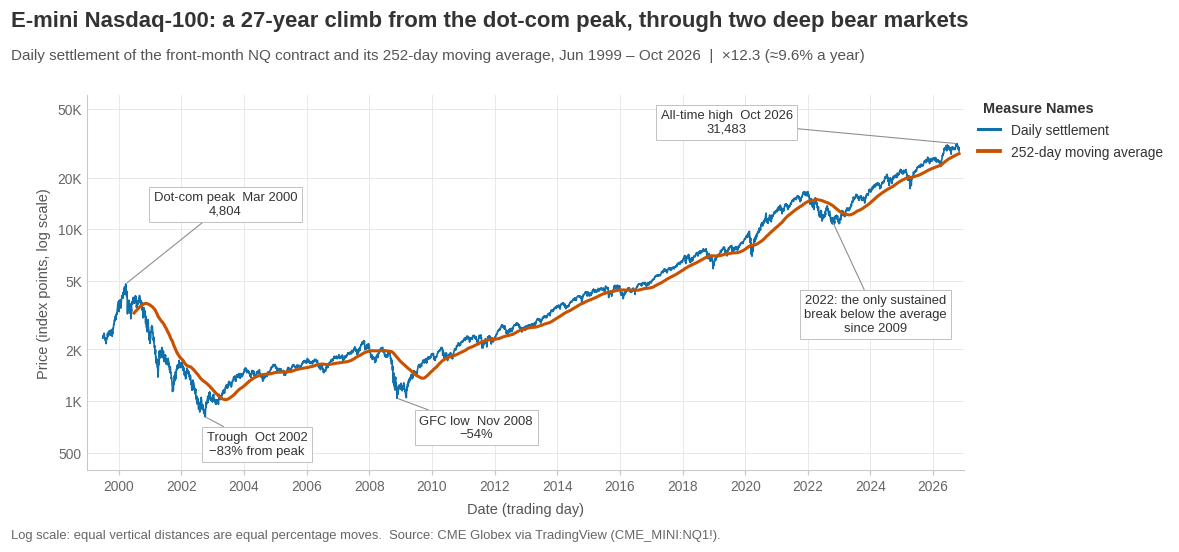

In [67]:
def fig_price(df):
    c = df["Close"]
    fig, ax = worksheet()
    ax.plot(c, color=BLUE, lw=1.1, zorder=4)
    ax.plot(df["MA_252"], color=ORANGE, lw=2, zorder=5)
    ax.set_yscale("log")
    ax.set_ylim(400, 60000)
    ax.yaxis.set_major_locator(mtick.FixedLocator([500, 1000, 2000, 5000, 10000, 20000, 50000]))
    ax.yaxis.set_minor_locator(mtick.NullLocator())
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(k_fmt))
    date_axis(ax, df)
    ax.set_ylabel("Price (index points, log scale)")

    dot = episode(c, *EPISODES["Dot-com bust"])
    gfc = episode(c, *EPISODES["GFC"])
    ath = c.idxmax()
    years = (c.index[-1] - c.index[0]).days / 365.25
    annotate(ax, f"Dot-com peak  {dot['peak']:%b %Y}\n{c[dot['peak']]:,.0f}",
             (dot["peak"], c[dot["peak"]]), (pd.Timestamp("2003-06-01"), 14000))
    annotate(ax, f"Trough  {dot['trough']:%b %Y}\n{pct(dot['depth'])} from peak",
             (dot["trough"], c[dot["trough"]]), (pd.Timestamp("2004-06-01"), 560))
    annotate(ax, f"GFC low  {gfc['trough']:%b %Y}\n{pct(gfc['depth'])}",
             (gfc["trough"], c[gfc["trough"]]), (pd.Timestamp("2011-06-01"), 700))
    annotate(ax, f"All-time high  {ath:%b %Y}\n{c[ath]:,.0f}",
             (ath, c[ath]), (pd.Timestamp("2019-06-01"), 42000))
    annotate(ax, "2022: the only sustained\nbreak below the average\nsince 2009",
             (pd.Timestamp("2022-10-15"), c["2022-10-15":].iloc[0]),
             (pd.Timestamp("2024-03-01"), 3200))

    titles(fig, "E-mini Nasdaq-100: a 27-year climb from the dot-com peak, through two deep bear markets",
           f"Daily settlement of the front-month NQ contract and its 252-day moving average, "
           f"{c.index[0]:%b %Y} – {c.index[-1]:%b %Y}  |  ×{c.iloc[-1] / c.iloc[0]:.1f} "
           f"(≈{(c.iloc[-1] / c.iloc[0]) ** (1 / years) - 1:.1%} a year)")
    legend_card(fig, "Measure Names", [
        Line2D([], [], color=BLUE, lw=2, label="Daily settlement"),
        Line2D([], [], color=ORANGE, lw=2.5, label="252-day moving average")])
    caption(fig, "Log scale: equal vertical distances are equal percentage moves.  "
                 "Source: CME Globex via TradingView (CME_MINI:NQ1!).", y=0.0)
    save(fig, "V1_price_trend_log_ma252.png")


fig_price(df)

**Insight.** On a log scale, equal vertical distances mean equal percentage moves. From 2,325.50 at the end of June 1999, the contract rose to 28,534 (×12.3, about 9.6% a year in price terms). The 2000 peak of 4,804 was followed by an 83% collapse. Since 2009 the trend has been steeper and steadier, with 2022 the only sustained break below the 252-day average.

### V2. Drawdown from the previous high (O1)

**Tableau build:** `Drawdown` (or `SUM([Close]) / RUNNING_MAX(SUM([Close])) - 1`) as an Area mark, with the axis fixed from −100% to 0%. Place it directly under V1 with dates aligned.

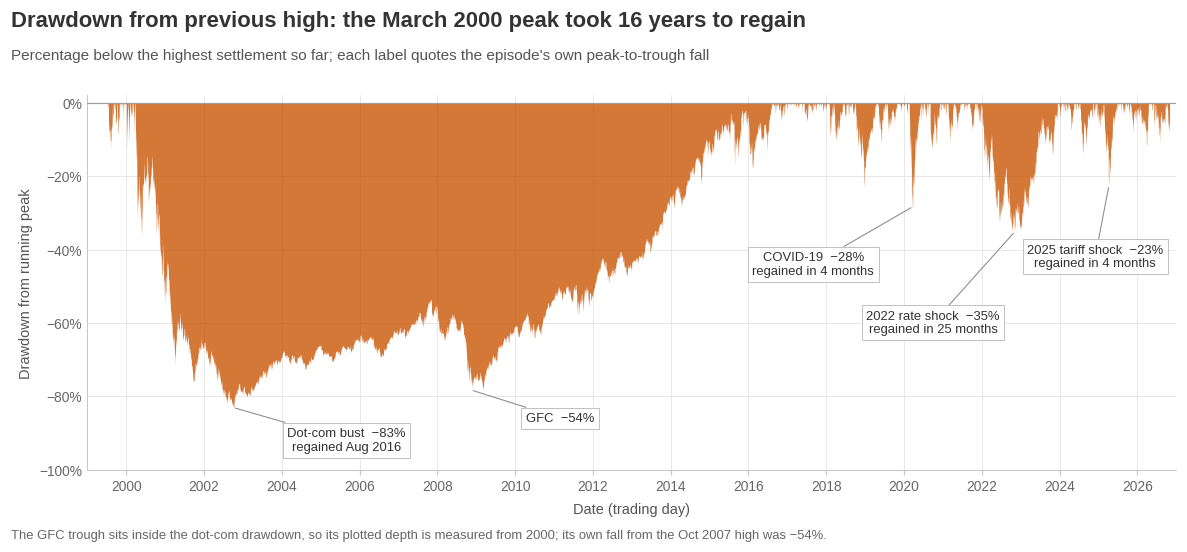

In [68]:
def fig_drawdown(df):
    c = df["Close"]
    dd = df["Drawdown"] * 100
    fig, ax = worksheet(legend=False)
    ax.fill_between(dd.index, dd, 0, color=ORANGE, alpha=0.78, lw=0, zorder=3)
    ax.axhline(0, color="#9E9E9E", lw=0.8, zorder=4)
    ax.set_ylim(-100, 2)
    ax.yaxis.set_major_locator(mtick.MultipleLocator(20))
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.0f}%".replace("-", "−")))
    date_axis(ax, df)
    ax.set_ylabel("Drawdown from running peak")

    text_pos = {"Dot-com bust": (pd.Timestamp("2005-09-01"), -92),
                "GFC": (pd.Timestamp("2011-03-01"), -86),
                "COVID-19": (pd.Timestamp("2017-09-01"), -44),
                "2022 rate shock": (pd.Timestamp("2020-10-01"), -60),
                "2025 tariff shock": (pd.Timestamp("2024-12-01"), -42)}
    for name, (start, end) in EPISODES.items():
        e = episode(c, start, end)
        extra = (f"\nregained {e['regained']:%b %Y}" if name == "Dot-com bust" else
                 f"\nregained in {(e['regained'] - e['peak']).days / 30.44:.0f} months"
                 if e["regained"] is not None and name != "GFC" else "")
        annotate(ax, f"{name}  {pct(e['depth'])}{extra}", (e["trough"], dd[e["trough"]]),
                 text_pos[name])

    dot = episode(c, *EPISODES["Dot-com bust"])
    wait = (dot["regained"] - dot["peak"]).days / 365.25
    titles(fig, f"Drawdown from previous high: the March 2000 peak took {wait:.0f} years to regain",
           "Percentage below the highest settlement so far; each label quotes the episode's own "
           "peak-to-trough fall")
    caption(fig, "The GFC trough sits inside the dot-com drawdown, so its plotted depth is measured "
                 "from 2000; its own fall from the Oct 2007 high was "
                 f"{pct(episode(c, *EPISODES['GFC'])['depth'])}.", y=0.0)
    save(fig, "V2_drawdown_underwater.png")


fig_drawdown(df)

**Insight.** Buyers at the March 2000 peak waited until August 2016, more than 16 years, to break even in price terms (see the episode table in §5.4). The global financial crisis cut a further 54% from the October 2007 high. Later declines were sharp but recovered faster: COVID −28% (regained in 3.5 months), 2022 −35% (two years), 2025 −23% (4 months).

### V3. Calendar-year returns (O1)

**Tableau build:** discrete `YEAR(Date)` on Columns, annual return on Rows, colour by sign (Color Blind palette: blue gain / orange loss, never red/green). Shade the partial first and last years lighter. Analytics pane → Median reference line.

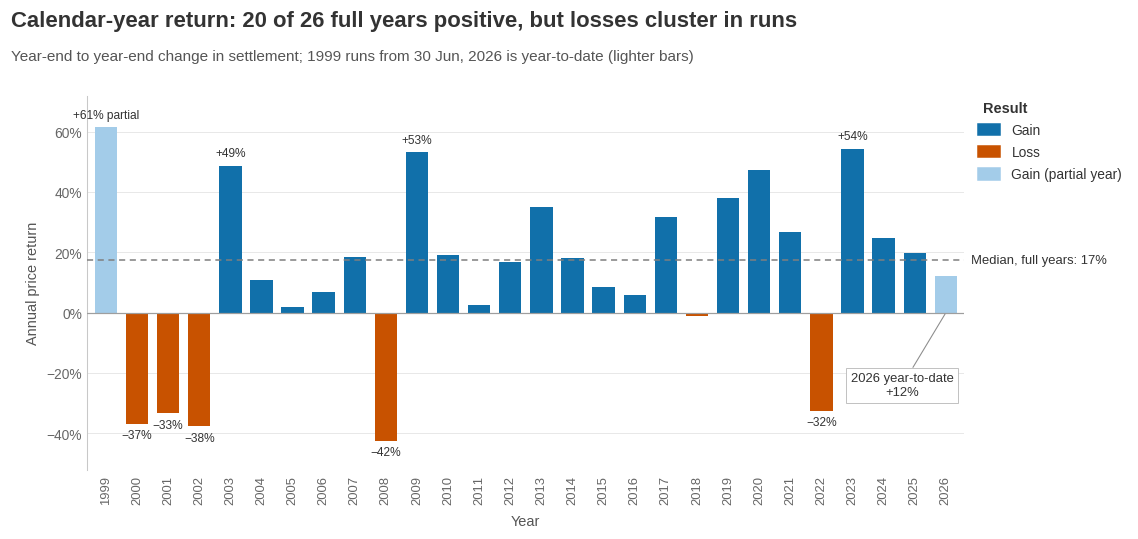

In [69]:
def fig_annual(df):
    ann = annual_returns(df) * 100
    first, last = ann.index.min(), ann.index.max()
    full = ann.loc[first + 1: last - 1]
    fig, ax = worksheet()
    x = np.arange(len(ann))
    partial = ann.index.isin([first, last])
    colours = np.where(ann >= 0, np.where(partial, LIGHT_BLUE, BLUE),
                       np.where(partial, LIGHT_ORANGE, ORANGE))
    ax.bar(x, ann.values, color=colours, width=0.72, zorder=3)
    ax.axhline(0, color="#9E9E9E", lw=0.8, zorder=4)
    ref_line(ax, full.median(), f"Median, full years: {full.median():.0f}%")

    annotate(ax, f"{last} year-to-date\n{pct(ann[last] / 100, sign=True)}", (len(ann) - 1, 0),
             (len(ann) - 2.4, -24))
    label_years = {2000, 2001, 2002, 2003, 2008, 2009, 2022, 2023, first}
    for i, (yr, v) in enumerate(ann.items()):
        if yr in label_years:
            tag = " partial" if yr == first else ""
            ax.text(i, v + (2 if v >= 0 else -2), pct(v / 100, sign=True) + tag,
                    ha="center", va="bottom" if v >= 0 else "top", fontsize=7.8, color=TITLE,
                    rotation=0, zorder=5)
    ax.set_xticks(x, ann.index.astype(str), rotation=90, fontsize=8.5)
    ax.tick_params(axis="x", length=0, pad=4)
    ax.set_xlim(-0.6, len(ann) - 0.4)
    ax.set_ylim(-52, 72)
    ax.grid(axis="x", visible=False)
    ax.spines["bottom"].set_visible(False)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.0f}%".replace("-", "−")))
    ax.set_ylabel("Annual price return")
    ax.set_xlabel("Year", labelpad=6)

    titles(fig, f"Calendar-year return: {(full > 0).sum()} of {len(full)} full years positive, "
                "but losses cluster in runs",
           f"Year-end to year-end change in settlement; {first} runs from {df.index[0]:%d %b}, "
           f"{last} is year-to-date (lighter bars)")
    legend_card(fig, "Result", [
        Patch(color=BLUE, label="Gain"), Patch(color=ORANGE, label="Loss"),
        Patch(color=LIGHT_BLUE, label="Gain (partial year)")])
    save(fig, "V3_annual_returns.png")


fig_annual(df)

**Insight.** 20 of 26 full years ended higher, with a median gain of 17%. The losing years cluster: 2000–02 fell three years running (−37%, −33%, −38%). The other large losses, 2008 (−42%) and 2022 (−32%), were each followed by a rebound of more than 50%.

### V4. Rolling volatility regimes (O2)

**Tableau build:** `Rolling_Vol_21d_Ann` (or `WINDOW_STDEV([Log Return], -20, 0) * SQRT(252)`) as a line. Analytics pane → reference lines at the Median and the 90th percentile. Colour the area above the stress line.

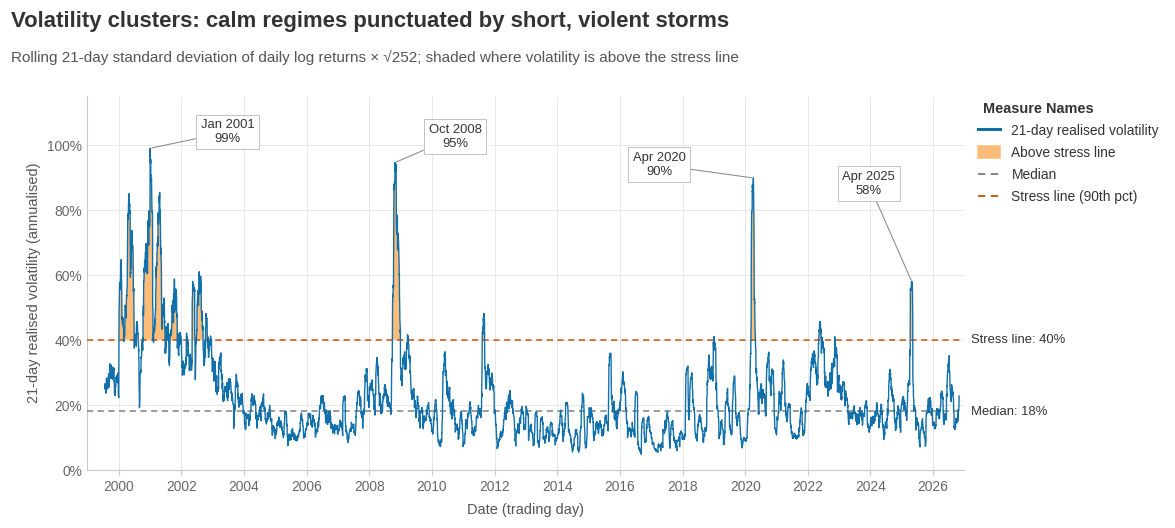

In [70]:
def fig_volatility(df):
    rv = df["Rolling_Vol_21d_Ann"].dropna() * 100
    med, p90 = rv.median(), rv.quantile(0.9)
    fig, ax = worksheet()
    ax.fill_between(rv.index, p90, rv, where=rv > p90, color=LIGHT_ORANGE, lw=0,
                    interpolate=True, zorder=2)
    ax.plot(rv, color=BLUE, lw=0.9, zorder=4)
    ref_line(ax, med, f"Median: {med:.0f}%")
    ref_line(ax, p90, f"Stress line: {p90:.0f}%", color=ORANGE)
    date_axis(ax, df)
    ax.set_ylim(0, 115)
    ax.yaxis.set_major_locator(mtick.MultipleLocator(20))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_ylabel("21-day realised volatility (annualised)")

    for (start, end), dx, dy in [(("2000-01", "2002-12"), 900, 5), (("2008-01", "2009-06"), 700, 8),
                                 (("2020-01", "2020-12"), -1100, 4), (("2025-01", "2025-12"), -500, 30)]:
        t = rv[start:end].idxmax()
        annotate(ax, f"{t:%b %Y}\n{rv[t]:.0f}%", (t, rv[t]), (t + pd.Timedelta(days=dx), rv[t] + dy))

    titles(fig, "Volatility clusters: calm regimes punctuated by short, violent storms",
           "Rolling 21-day standard deviation of daily log returns × √252; "
           "shaded where volatility is above the stress line")
    legend_card(fig, "Measure Names", [
        Line2D([], [], color=BLUE, lw=2, label="21-day realised volatility"),
        Patch(color=LIGHT_ORANGE, label="Above stress line"),
        Line2D([], [], color=REF, lw=1.2, ls=(0, (4, 3)), label="Median"),
        Line2D([], [], color=ORANGE, lw=1.2, ls=(0, (4, 3)), label="Stress line (90th pct)")])
    save(fig, "V4_rolling_volatility_regimes.png")


fig_volatility(df)

**Insight.** Volatility usually sits near its 18% median but spikes three to five times higher: 99% in January 2001, 95% in late 2008, 90% in March 2020 and 58% in April 2025. The autocorrelation table in §5.3 confirms the clustering: absolute returns stay autocorrelated (0.30 at lag 1, 0.26 at lag 21) while returns themselves do not (−0.05). Volatility also rises as prices fall (correlation −0.35). Storms persist: when volatility is above the 40% stress line, there is a 65% chance it is still above the line a month later, against a 10% base rate (§5.9).

### V5. Distribution of daily returns: fat tails (O2)

**Tableau build:** create bins on `Log_Return` (size 0.0025), use `CNT` on Rows with a logarithmic y-axis, and add a normal-curve calculated field on the same axis.

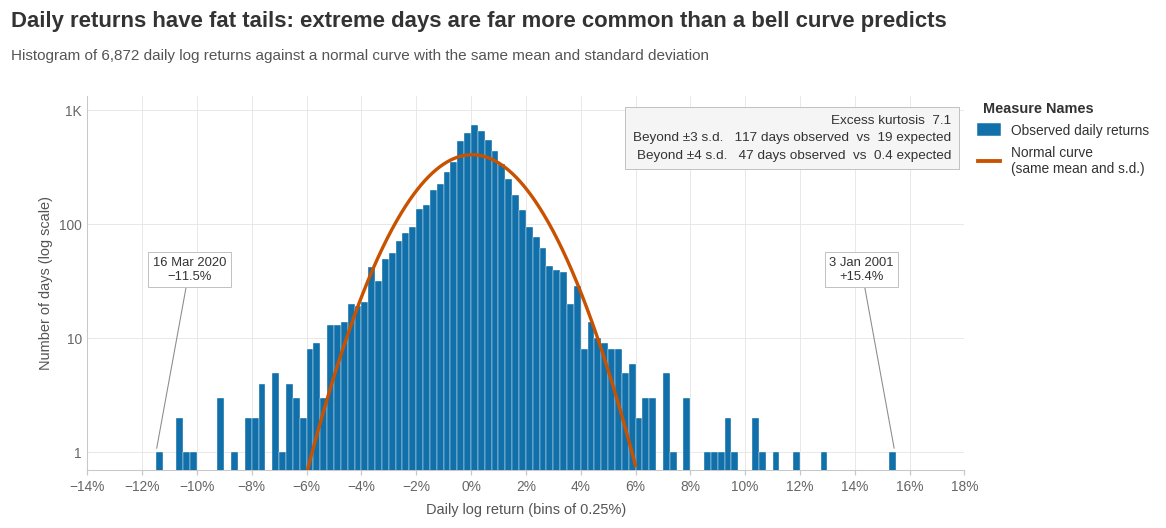

In [71]:
def fig_distribution(df):
    r = df["Log_Return"].dropna() * 100
    bins = np.arange(-12.5, 16.75, 0.25)
    counts, edges = np.histogram(r, bins=bins)
    centres = edges[:-1] + 0.125
    fig, ax = worksheet()
    ax.bar(centres, np.where(counts > 0, counts, np.nan), width=0.25, color=BLUE,
           edgecolor=WHITE, linewidth=0.25, zorder=3)
    x = np.linspace(-6, 6, 600)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()) * len(r) * 0.25, color=ORANGE, lw=2.2, zorder=4)
    ax.set_yscale("log")
    ax.set_ylim(0.7, counts.max() * 1.8)
    ax.yaxis.set_major_locator(mtick.FixedLocator([1, 10, 100, 1000]))
    ax.yaxis.set_minor_locator(mtick.NullLocator())
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(k_fmt))
    ax.set_xlim(-14, 18)
    ax.xaxis.set_major_locator(mtick.MultipleLocator(2))
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.0f}%".replace("-", "−")))
    ax.set_xlabel("Daily log return (bins of 0.25%)", labelpad=6)
    ax.set_ylabel("Number of days (log scale)")

    z = (r - r.mean()) / r.std()
    ax.text(0.985, 0.95,
            f"Excess kurtosis  {stats.kurtosis(r):.1f}\n"
            f"Beyond ±3 s.d.   {(z.abs() > 3).sum()} days observed  vs  "
            f"{len(r) * 2 * stats.norm.sf(3):.0f} expected\n"
            f"Beyond ±4 s.d.   {(z.abs() > 4).sum()} days observed  vs  "
            f"{len(r) * 2 * stats.norm.sf(4):.1f} expected",
            transform=ax.transAxes, ha="right", va="top", fontsize=8.8, color=TITLE,
            linespacing=1.6, zorder=6,
            bbox=dict(boxstyle="square,pad=0.6", fc="#F5F5F5", ec="#BDBDBD", lw=0.6))
    lo, hi = r.idxmin(), r.idxmax()
    annotate(ax, f"{lo.day} {lo:%b %Y}\n{pct(r[lo] / 100, 1, sign=True)}", (r[lo], 1.05), (r[lo] + 1.2, 40))
    annotate(ax, f"{hi.day} {hi:%b %Y}\n{pct(r[hi] / 100, 1, sign=True)}", (r[hi], 1.05), (r[hi] - 1.2, 40))

    titles(fig, "Daily returns have fat tails: extreme days are far more common than a bell curve predicts",
           f"Histogram of {len(r):,} daily log returns against a normal curve with the same mean "
           "and standard deviation")
    legend_card(fig, "Measure Names", [
        Patch(color=BLUE, label="Observed daily returns"),
        Line2D([], [], color=ORANGE, lw=2.5, label="Normal curve\n(same mean and s.d.)")])
    save(fig, "V5_return_distribution_fat_tails.png")


fig_distribution(df)

**Insight.** A normal distribution predicts about 19 three-sigma days in 27 years; the contract produced 117. Beyond four sigma the bell curve expects fewer than one such day; the data contain 47. Excess kurtosis is 7.1 and the Jarque-Bera test rejects normality decisively (§5.2), so Gaussian risk models would badly underestimate crash frequency.

### V6. Trend-regime scorecard (O3)

**Tableau build:** `Measure Names` (the four metrics) on Columns, `Measure Values` on Rows, `Trend_Regime` on Colour, value labels on and the y-axis hidden. Alternatively, use four small sheets in a dashboard strip.

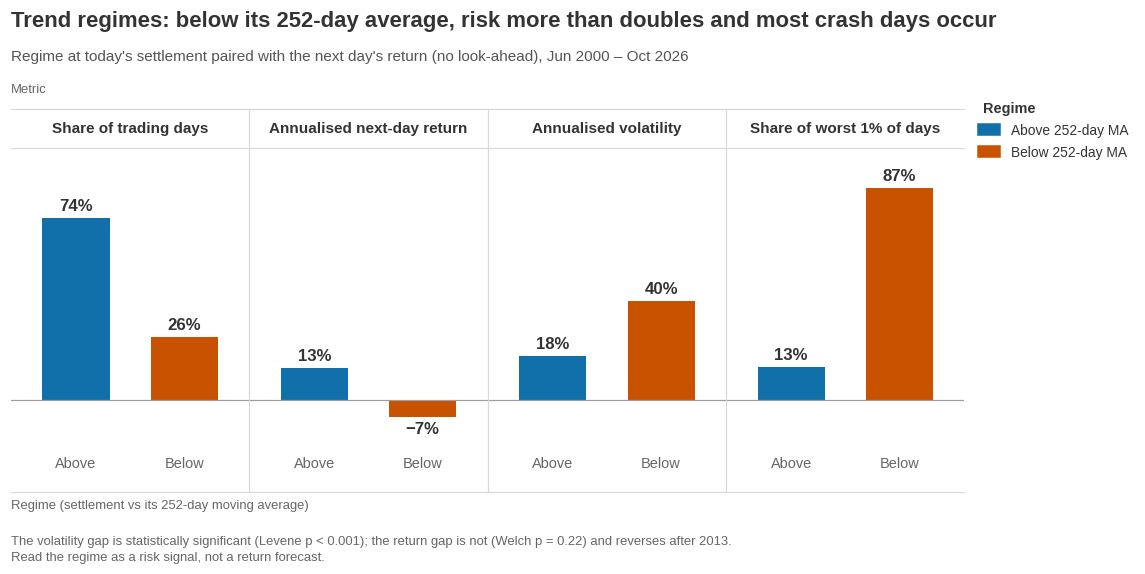

In [72]:
def fig_regime(df):
    t = regime_table(df).loc[["Above 252-day MA", "Below 252-day MA"]]
    metrics = [("share_days", "Share of trading days"),
               ("ann_return", "Annualised next-day return"),
               ("ann_vol", "Annualised volatility"),
               ("share_worst_1pct", "Share of worst 1% of days")]
    fig = plt.figure(figsize=(11, 5))
    left, right, bottom, top = 0.012, 0.80, 0.17, 0.71
    w = (right - left) / 4
    lo = min(0, (t["ann_return"] * 100).min() * 2.8)
    hi = (t[[m for m, _ in metrics]] * 100).max().max() * 1.18
    for k, (col, name) in enumerate(metrics):
        ax = fig.add_axes([left + k * w, bottom, w, top - bottom])
        vals = t[col].values * 100
        ax.bar([0, 1], vals, color=[BLUE, ORANGE], width=0.62, zorder=3)
        ax.axhline(0, color="#9E9E9E", lw=0.8, zorder=4)
        for i, v in enumerate(vals):
            ax.text(i, v + (2 if v >= 0 else -2), pct(v / 100), ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=11, fontweight="semibold", color=TITLE)
        ax.set_ylim(lo, hi)
        ax.set_xlim(-0.6, 1.6)
        ax.set_xticks([0, 1], ["Above", "Below"], fontsize=9.5)
        ax.tick_params(axis="x", length=0, pad=6)
        ax.yaxis.set_visible(False)
        ax.grid(False)
        for s in ("left", "bottom"):
            ax.spines[s].set_visible(False)
        # Tableau column divider between panes
        if k:
            fig.add_artist(Line2D([left + k * w] * 2, [bottom - 0.08, top + 0.075], color="#D9D9D9", lw=0.8))
        fig.text(left + (k + 0.5) * w, top + 0.04, name, ha="center", va="center", fontsize=10,
                 fontweight="semibold", color=TITLE)
    # Header band rules, as Tableau draws them around a discrete column header
    for y in (top + 0.075, top + 0.005, bottom - 0.08):
        fig.add_artist(Line2D([left, right], [y, y], color="#D9D9D9", lw=0.8))
    fig.text(left, top + 0.10, "Metric", fontsize=8.5, color=TICK_INK, va="bottom")
    fig.text(left, bottom - 0.095, "Regime (settlement vs its 252-day moving average)",
             fontsize=8.5, color=TICK_INK, va="top")

    titles(fig, "Trend regimes: below its 252-day average, risk more than doubles and most crash days occur",
           "Regime at today's settlement paired with the next day's return (no look-ahead), "
           f"{df['MA_252'].first_valid_index():%b %Y} – {df.index[-1]:%b %Y}")
    legend_card(fig, "Regime", [Patch(color=BLUE, label="Above 252-day MA"),
                                Patch(color=ORANGE, label="Below 252-day MA")])
    caption(fig, "The volatility gap is statistically significant (Levene p < 0.001); the return gap is not "
                 f"(Welch p = {regime_tests(regime_split(df))['p_return']:.2f}) and reverses after 2013.\n"
                 "Read the regime as a risk signal, not a return forecast.", y=-0.04)
    save(fig, "V6_trend_regime_scorecard.png")


fig_regime(df)

**Insight.** The contract settled above its one-year average on 74% of days, when volatility averaged 18%. In the other 26% of days volatility was 40%, and those days contained 87% of the worst 1% of sessions. The robustness tests in §5.8 show this **risk** separation holds for every moving-average length and in both halves of the sample. The **return** gap (+12.8% vs −7.0% a year) is not statistically significant (p = 0.22) and reverses after 2013, when below-average days were often sharp rebounds. So the honest reading is that the 252-day line is a risk thermometer, not a return forecast.

## 7. A1 poster layout reference

The brief requires an A1 poster (594 × 841 mm) with clear sections, minimal text and well-integrated visuals. `fig_poster_layout` composes the six chart renders into a portrait A1 layout:

- a header band with the title and author;
- three top panels: Introduction with the research questions, Data and Method, and four headline-number tiles;
- the charts in a 2 × 3 grid, each with a one-line caption tagged by objective;
- Discussion, Conclusion and References along the bottom.

The layout uses one font family, the same colours as the charts, and about 35% white space. In the submitted poster, replace each image with its Tableau export, using chart fonts of at least 18 pt at A1 size.

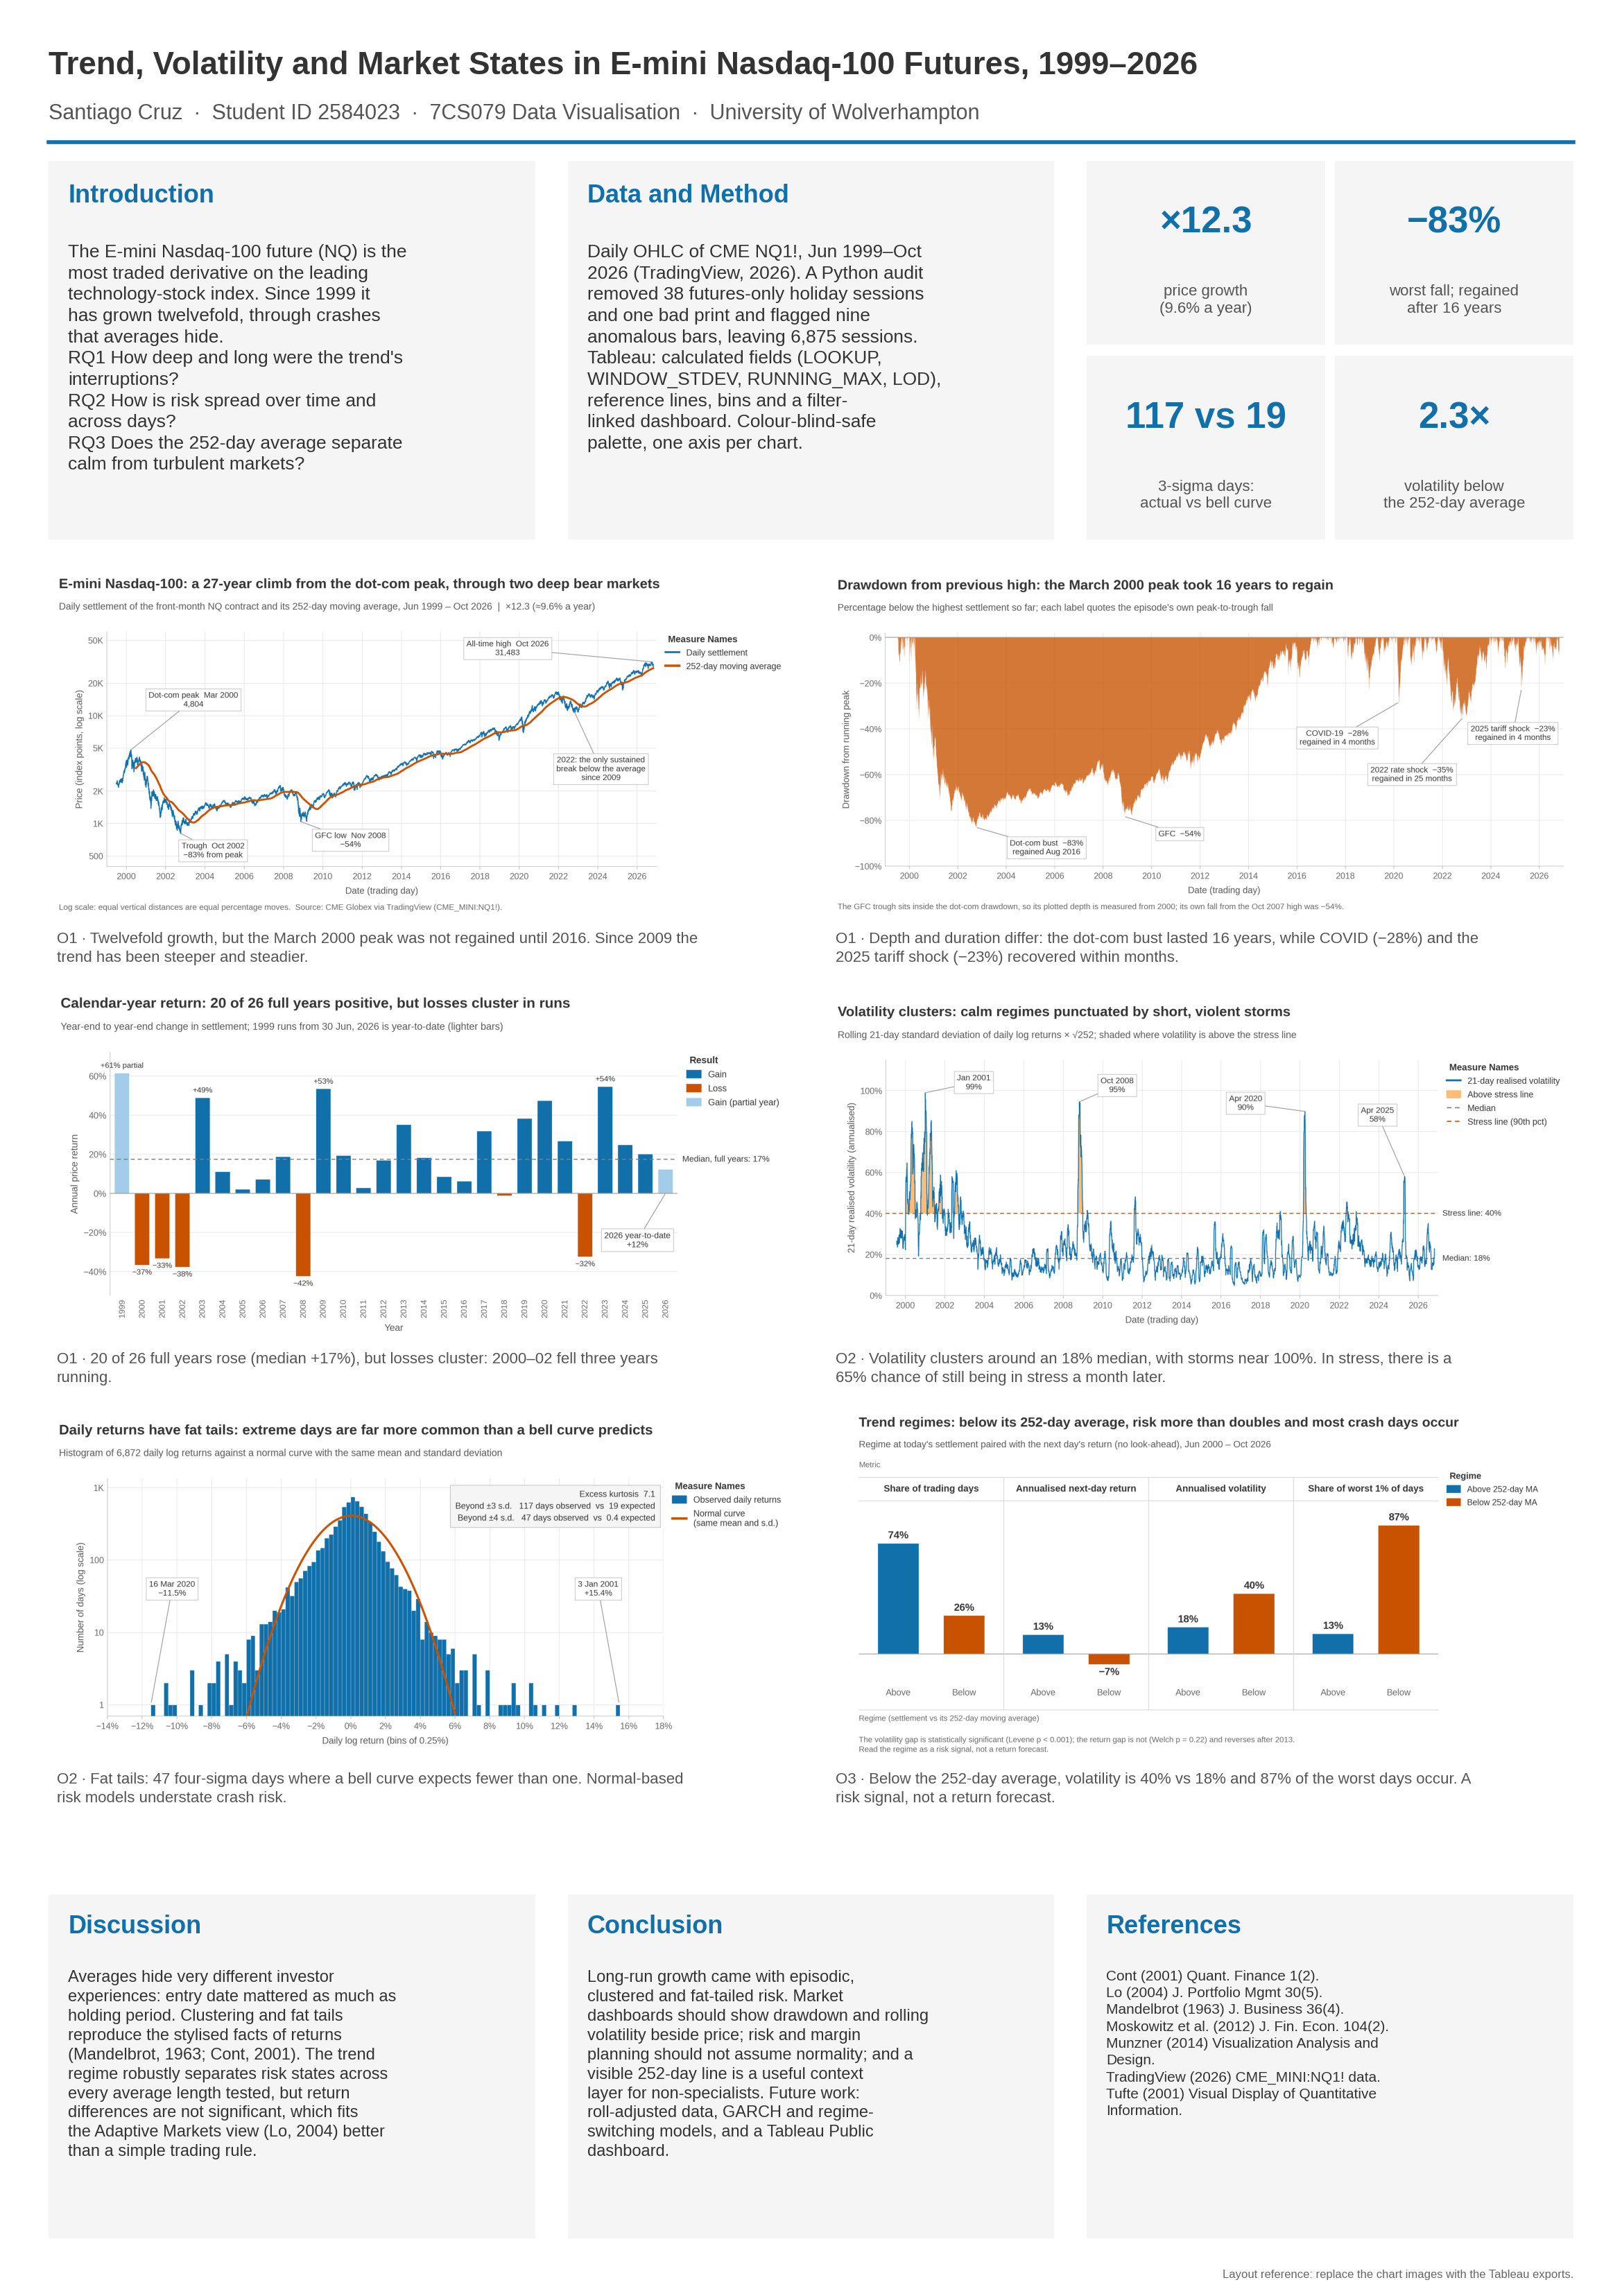

In [73]:
def fig_poster_layout(df):
    """A1 portrait layout reference (594 x 841 mm) composed from the six chart PNGs."""
    c, r = df["Close"], df["Log_Return"].dropna()
    years = (c.index[-1] - c.index[0]).days / 365.25
    z = (r - r.mean()) / r.std()
    dot = episode(c, *EPISODES["Dot-com bust"])
    t = regime_tests(regime_split(df))
    ann = annual_returns(df)
    full = ann.loc[c.index[0].year + 1: c.index[-1].year - 1]
    rv = df["Rolling_Vol_21d_Ann"]

    fig = plt.figure(figsize=(23.39, 33.11))
    fig.patch.set_facecolor(SURFACE)

    def box(x, y, w, h, heading, body, width, size=19):
        ax = fig.add_axes([x, y, w, h])
        ax.axis("off")
        ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, fc=NEUTRAL, ec="none"))
        ax.text(0.04, 0.94, heading, fontsize=26, fontweight="bold", color=UP, va="top",
                transform=ax.transAxes)
        ax.text(0.04, 0.78, "\n".join(textwrap.fill(p, width) for p in body.split("\n")),
                fontsize=size, color=INK, va="top", linespacing=1.35, transform=ax.transAxes)

    def chart(x, y, w, h, png, caption):
        ax = fig.add_axes([x, y + 0.028, w, h - 0.028])
        ax.imshow(mpimg.imread(FIG_DIR / png))
        ax.axis("off")
        fig.text(x + 0.005, y + 0.024, textwrap.fill(caption, 92), fontsize=16, color=INK_2,
                 va="top", linespacing=1.35)

    # Header band
    fig.text(0.03, 0.978, "Trend, Volatility and Market States in E-mini Nasdaq-100 Futures, 1999–2026",
             fontsize=33, fontweight="bold", color=INK, va="top")
    fig.text(0.03, 0.955, "Santiago Cruz  ·  Student ID 2584023  ·  7CS079 Data Visualisation  ·  "
             "University of Wolverhampton", fontsize=22, color=INK_2, va="top")
    fig.add_artist(plt.Line2D([0.03, 0.97], [0.938, 0.938], color=UP, lw=4))

    # Row 1: introduction, data & method, headline numbers
    box(0.03, 0.765, 0.30, 0.165, "Introduction",
        "The E-mini Nasdaq-100 future (NQ) is the most traded derivative on the leading "
        "technology-stock index. Since 1999 it has grown twelvefold, through crashes that "
        "averages hide.\nRQ1 How deep and long were the trend's interruptions?\n"
        "RQ2 How is risk spread over time and across days?\n"
        "RQ3 Does the 252-day average separate calm from turbulent markets?", 40)
    box(0.35, 0.765, 0.30, 0.165, "Data and Method",
        f"Daily OHLC of CME NQ1!, {c.index[0]:%b %Y}–{c.index[-1]:%b %Y} (TradingView, 2026). "
        "A Python audit removed 38 futures-only holiday sessions and one bad print and "
        f"flagged nine anomalous bars, leaving {len(df):,} sessions.\nTableau: calculated fields "
        "(LOOKUP, WINDOW_STDEV, RUNNING_MAX, LOD), reference lines, bins and a "
        "filter-linked dashboard. Colour-blind-safe palette, one axis per chart.", 40)
    tiles = [(f"×{c.iloc[-1] / c.iloc[0]:.1f}", f"price growth\n({(c.iloc[-1] / c.iloc[0]) ** (1 / years) - 1:.1%} a year)"),
             (pct(dot["depth"]), f"worst fall; regained\nafter {(dot['regained'] - dot['peak']).days / 365.25:.0f} years"),
             (f"{(z.abs() > 3).sum()} vs {len(r) * 2 * stats.norm.sf(3):.0f}", "3-sigma days:\nactual vs bell curve"),
             (f"{t['vol_below'] / t['vol_above']:.1f}×", "volatility below\nthe 252-day average")]
    for i, (big, small) in enumerate(tiles):
        ax = fig.add_axes([0.67 + (i % 2) * 0.153, 0.850 - (i // 2) * 0.085, 0.147, 0.080])
        ax.axis("off")
        ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, fc=NEUTRAL, ec="none"))
        ax.text(0.5, 0.66, big, fontsize=38, fontweight="bold", color=UP, ha="center", va="center")
        ax.text(0.5, 0.24, small, fontsize=16, color=INK_2, ha="center", va="center")

    # Rows 2-4: the six charts, two per row
    captions = [
        ("V1_price_trend_log_ma252.png", f"O1 · Twelvefold growth, but the March 2000 peak was not regained until "
         f"{dot['regained']:%Y}. Since 2009 the trend has been steeper and steadier."),
        ("V2_drawdown_underwater.png", "O1 · Depth and duration differ: the dot-com bust lasted 16 years, while "
         "COVID (−28%) and the 2025 tariff shock (−23%) recovered within months."),
        ("V3_annual_returns.png", f"O1 · {(full > 0).sum()} of {len(full)} full years rose (median "
         f"{full.median():+.0%}), but losses cluster: 2000–02 fell three years running."),
        ("V4_rolling_volatility_regimes.png", f"O2 · Volatility clusters around an {rv.median():.0%} median, "
         "with storms near 100%. In stress, there is a 65% chance of still being in stress a month later."),
        ("V5_return_distribution_fat_tails.png", f"O2 · Fat tails: {(z.abs() > 4).sum()} four-sigma days where "
         "a bell curve expects fewer than one. Normal-based risk models understate crash risk."),
        ("V6_trend_regime_scorecard.png", f"O3 · Below the 252-day average, volatility is {t['vol_below']:.0%} vs "
         f"{t['vol_above']:.0%} and {t['worst1pct_below']:.0%} of the worst days occur. A risk signal, not a "
         "return forecast."),
    ]
    for i, (png, cap) in enumerate(captions):
        chart(0.03 + (i % 2) * 0.48, 0.570 - (i // 2) * 0.183, 0.46, 0.183, png, cap)

    # Row 5: discussion, conclusion, references
    box(0.03, 0.025, 0.30, 0.150, "Discussion",
        "Averages hide very different investor experiences: entry date mattered as much as "
        "holding period. Clustering and fat tails reproduce the stylised facts of returns "
        "(Mandelbrot, 1963; Cont, 2001). The trend regime robustly separates risk states across "
        "every average length tested, but return differences are not significant, which fits "
        "the Adaptive Markets view (Lo, 2004) better than a simple trading rule.", 44, 17)
    box(0.35, 0.025, 0.30, 0.150, "Conclusion",
        "Long-run growth came with episodic, clustered and fat-tailed risk. Market dashboards "
        "should show drawdown and rolling volatility beside price; risk and margin planning "
        "should not assume normality; and a visible 252-day line is a useful context layer for "
        "non-specialists. Future work: roll-adjusted data, GARCH and regime-switching models, "
        "and a Tableau Public dashboard.", 44, 17)
    box(0.67, 0.025, 0.30, 0.150, "References",
        "Cont (2001) Quant. Finance 1(2).\nLo (2004) J. Portfolio Mgmt 30(5).\n"
        "Mandelbrot (1963) J. Business 36(4).\nMoskowitz et al. (2012) J. Fin. Econ. 104(2).\n"
        "Munzner (2014) Visualization Analysis and Design.\nTradingView (2026) CME_MINI:NQ1! data.\n"
        "Tufte (2001) Visual Display of Quantitative Information.", 48, 15)
    fig.text(0.97, 0.008, "Layout reference: replace the chart images with the Tableau exports.",
             fontsize=12, color=MUTED, ha="right")
    fig.savefig(FIG_DIR / "poster_layout_A1_reference.png", dpi=100)
    plt.close(fig)


fig_poster_layout(df)
from IPython.display import Image
Image(filename=str(FIG_DIR / "poster_layout_A1_reference.png"), width=900)

## 8. Summary of key numbers

These figures feed the poster captions and Appendix B of the report.

In [74]:
reg = regime_table(df)
above, below = reg.loc["Above 252-day MA"], reg.loc["Below 252-day MA"]
dot = episode(c, *EPISODES["Dot-com bust"])
pd.Series({
    "Sessions after cleaning": f"{len(df):,} ({df.index[0].date()} to {df.index[-1].date()})",
    "Start / end settlement": f"{c.iloc[0]:,.2f} -> {c.iloc[-1]:,.2f} (x{c.iloc[-1] / c.iloc[0]:.1f})",
    "Price CAGR": f"{(c.iloc[-1] / c.iloc[0]) ** (1 / years) - 1:.1%}",
    "Annualised volatility": f"{r.std() * np.sqrt(252):.1%}",
    "Skew / excess kurtosis": f"{stats.skew(r):.2f} / {stats.kurtosis(r):.2f}",
    "Days beyond ±3 s.d. / ±4 s.d.": f"{(z.abs() > 3).sum()} (normal {len(r) * 2 * stats.norm.sf(3):.0f}) / "
                                   f"{(z.abs() > 4).sum()} (normal {len(r) * 2 * stats.norm.sf(4):.1f})",
    "Max drawdown": f"{dot['depth']:.1%} ({dot['peak']:%d %b %Y} -> {dot['trough']:%d %b %Y}; "
                    f"regained {dot['regained']:%d %b %Y})",
    "All-time high": f"{c.max():,.2f} on {c.idxmax().date()}",
    "Positive full years / median": f"{(full > 0).sum()} of {len(full)} / {full.median():+.1%}",
    "21-day vol median / 90th pct": f"{rv.median():.1%} / {rv.quantile(.9):.1%}",
    "Days above / below 252-day MA": f"{above['share_days']:.0%} / {below['share_days']:.0%}",
    "Ann. return above / below": f"{above['ann_return']:+.1%} / {below['ann_return']:+.1%}",
    "Ann. vol above / below": f"{above['ann_vol']:.1%} / {below['ann_vol']:.1%}",
    "Worst-1% days above / below": f"{above['share_worst_1pct']:.0%} / {below['share_worst_1pct']:.0%}",
    "Return gap significant? (Welch p)": f"No (p = {regime_tests(g252)['p_return']:.2f})",
    "Volatility gap significant? (Levene p)": f"Yes (p = {regime_tests(g252)['p_volatility']:.0e})",
    "P(stress in 21 days | stress today)": f"{persist:.0%} (base rate {stress.mean():.0%})",
}, name="value").to_frame()

,value
Sessions after cleaning,"6,875 (1999-06-30 to 2026-10-30)"
Start / end settlement,"2,325.50 -> 28,534.00 (x12.3)"
Price CAGR,9.6%
Annualised volatility,26.7%
Skew / excess kurtosis,-0.02 / 7.10
Days beyond ±3 s.d. / ±4 s.d.,117 (normal 19) / 47 (normal 0.4)
Max drawdown,-83.1% (24 Mar 2000 -> 09 Oct 2002; regained 1...
All-time high,"31,483.25 on 2026-10-06"
Positive full years / median,20 of 26 / +17.4%
21-day vol median / 90th pct,18.1% / 40.0%


## 9. Answers to the research questions

- **RQ1 (trend):** the interruptions were deep and very uneven in length. The dot-com bust took 83% off the price and lasted 16.4 years from peak to recovery; the GFC took 54% and 3.2 years. Post-2009 shocks of 23–35% recovered within 3.5 months to 2 years. Long-run growth (×12.3, 9.6% a year) therefore depended heavily on the entry date.
- **RQ2 (volatility):** risk is neither steady nor normally distributed. It clusters (a 65% chance of continued stress, against a 10% base rate), rises when prices fall (−0.35), and has fat tails (117 three-sigma days against 19 expected; 47 four-sigma days against 0.4).
- **RQ3 (regimes):** yes for risk, no for returns. Below the 252-day average, volatility more than doubles (40% vs 18%) and 87% of the worst days occur, robustly across every specification tested. The return difference is not statistically significant and reverses after 2013.

## 10. Limitations

- **Futures, not the index:** NQ returns are the index's price return plus the futures premium change. They exclude dividends and implicitly deduct financing, and the unadjusted continuous series carries small quarterly roll jumps.
- **Start date:** the contract launched in June 1999, so the series opens near the top of the dot-com bubble. This depresses the long-run growth rate and excludes earlier crises such as 1987.
- **Settlement timing:** in the early pit-trading years, daily bars do not line up exactly with the cash-index close, which adds noise to 1999–2002 returns.
- **In-sample regime statistics:** no transaction costs, roll slippage or whipsaw losses (140 crossings, with a median spell of 5 days). The return gap is not statistically significant, and the tests assume independent days, which volatility clustering partly violates.
- **Description, not explanation:** the charts show *what* happened; links to historical events come from the literature cited in the report.